# CS465 Machine Learning Project: will this close approach still be dangerous two days later?

**Dataset:** ESA Collision Avoidance Challenge (Conjunction Data Messages for ESA satellites, 2015–2019; Zenodo record 4463683, CC BY 4.0).
**Student:** Abdullah (ID and group members to be added)

This notebook is the complete, runnable pipeline for the project, organised in the order of the project rubric:

| Section | Rubric milestone |
|---|---|
| 1. Problem statement and objectives | Week 6 |
| 2. Data preparation | Week 7 |
| 3. Exploratory data analysis | Week 8 |
| 4. Feature engineering | Week 9 |
| 5. Model building and hyperparameter optimisation | Week 10 |
| 6. Model evaluation and comparison | Week 11 |
| 7. Robustness checks, insights and reporting | Weeks 12–13 |
| 8. Conclusion | Week 14 |

**How to run.** Open this notebook in the project folder (`satellite-collision/`) and run all cells. It needs `numpy`, `pandas`, `scikit-learn`, `tensorflow` and `matplotlib` (versions in `requirements.txt`). The cleaned event table shipped with the project (`data/processed/events.csv.gz`, 12 MB) is enough; the 221 MB raw database is optional (`python3 get_data.py` downloads it, and then Section 2 rebuilds the table from the raw messages and the CDM-level plots appear). Heavy steps (hyperparameter search, final fits, bootstrap) store their outputs in `results/nb_cache/`, so a re-run takes under a minute; delete that folder to recompute everything from scratch (about 3–5 minutes on a laptop, single core).

The supporting scripts `build_table.py`, `models.py`, `evaluate.py` and `paper_check.py` run the same pipeline over three data splits and 25 cross-validation folds (about two hours of compute); Section 7 loads their saved results from `results/`. The README documents them.

## 1. Problem statement and objectives

**The problem.** Every time a piece of space debris is predicted to pass close to an ESA satellite, the satellite operators receive a series of *Conjunction Data Messages* (CDMs) over the week before the time of closest approach (TCA). Each CDM carries an updated estimate of the collision probability (`risk`, as log10, so −6 means one in a million), the predicted miss distance, the relative speed, and the orbit and covariance information of both objects. The operator must decide **two days before closest approach** whether to plan an avoidance manoeuvre, because that is how long a manoeuvre takes to prepare. The difficulty is that the risk estimate keeps changing right up to the end: many approaches that look dangerous two days out turn out to be harmless, and a few that look harmless become dangerous.

**The prediction task.** Given only the CDMs received at least two days before closest approach, predict whether the **final** risk (the one in the last CDM, received inside the last day) will be at or above ESA's alert threshold of −6. This is a binary classification problem with a severe class imbalance (about 2 % of events end up high risk), and it has a strong, physically motivated baseline: ESA's own "naive forecast", which simply assumes the latest known risk will not change.

**Objectives.**

1. Build a leakage-free dataset: one row per close-approach event whose features come only from the CDMs available at decision time, and whose label comes from the final CDM.
2. Explore the data to understand the class imbalance, how the risk evolves, which quantities relate to the outcome, and which features are worth engineering.
3. Engineer features that summarise the history of each event, and scale/encode them for the models.
4. Train and tune four course models (logistic regression, decision tree, neural network, SVM) plus gradient boosting, choosing hyperparameters by cross-validation on the training data only.
5. Evaluate the models with metrics suited to an imbalanced alerting problem (precision, recall, F1, F2, PR-AUC, ROC-AUC, plus accuracy for completeness), compare them with ESA's naive forecast, and select the best model.
6. Check that the conclusions hold on other data splits (ESA's competition split, repeated cross-validation, held-out satellites), and interpret the results.

## 2. Data preparation

### 2.1 Setup

In [1]:
import os, sys, json, time, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
sys.path.insert(0, os.getcwd())          # the project's own modules: config.py, build_table.py
import config
from config import DATA, PROC, OUT, FIG, SEED, HIGH_RISK, CUTOFF_DAYS, FINAL_WITHIN_DAYS

RAW = os.path.join(DATA, "Collision Avoidance Challenge - Dataset", "raw_data", "raw_data_2015-2019.gz")
EVENTS = os.path.join(PROC, "events.csv.gz")
CACHE = os.path.join(OUT, "nb_cache"); os.makedirs(CACHE, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# A time budget lets the notebook be executed in several sittings (cached progress is kept).
# Leave NB_TIME_BUDGET unset to run everything in one go.
_DEADLINE = time.time() + float(os.environ.get("NB_TIME_BUDGET", "1e12"))
class TimeBudgetReached(Exception):
    pass
def check_budget():
    if time.time() > _DEADLINE:
        raise TimeBudgetReached("time budget reached; run the notebook again to continue (cached progress is kept)")

def cached_json(name, compute):
    p = os.path.join(CACHE, name + ".json")
    if os.path.exists(p):
        return json.load(open(p))
    v = compute(); text = json.dumps(v, indent=1)       # serialise first, so a failure never leaves a half-written file
    with open(p, "w") as fh:
        fh.write(text)
    return v

print("data folder:", DATA)
print("raw CDM database present:", os.path.exists(RAW))
print("event table present:", os.path.exists(EVENTS))

data folder: /sessions/gifted-lucid-mendel/mnt/cs465/Project/satellite-collision/data
raw CDM database present: True
event table present: True


### 2.2 Load the raw data and build the event table

The raw database has **one row per CDM** (199,082 rows, 103 columns, 15,321 events). The modelling table needs **one row per event**. `build_table.py` does this, following ESA's definitions from the competition and the paper (Uriot et al., *Astrodynamics* 2022):

* **Label.** `high_risk = 1` when the risk in the event's *last* CDM (smallest `time_to_tca`) is ≥ −6.
* **Inputs.** Only CDMs with `time_to_tca ≥ 2` days may be used, because the manoeuvre decision is taken two days out. Nothing from the last two days (and in particular nothing from the CDM that carries the label) enters the features.
* **Eligibility.** An event is kept only if its last CDM arrives within one day of closest approach (otherwise its "final" risk is not final) and it has at least one usable CDM. This is exactly ESA's filter for its test set.
* **Cleaning.** 488 CDMs arrive *after* closest approach (negative `time_to_tca`); they fall outside the usable window automatically. `event_id` and `mission_id` are identifiers, not physics, and are not features.

The cell below rebuilds the table from the raw file when it is present (about one minute), otherwise it loads the table shipped with the project. Either way the result is `data/processed/events.csv.gz`, the **cleaned dataset file**.

In [2]:
if os.path.exists(RAW):
    raw = pd.read_csv(RAW)
    print("raw CDMs:", raw.shape)
    display(raw.head(3))
    if not os.path.exists(EVENTS):
        import build_table
        build_table.main()
else:
    raw = None
    print("raw file not present: using the shipped event table (run get_data.py to download the 221 MB raw database)")

events = pd.read_csv(EVENTS, index_col=0)
print("event table:", events.shape, "| high-risk events:", int(events.high_risk.sum()),
      f"| base rate {events.high_risk.mean():.4f}")
events.head(3)

raw CDMs: (199082, 103)


,event_id,time_to_tca,mission_id,risk,max_risk_estimate,max_risk_scaling,miss_distance,relative_speed,relative_position_r,relative_position_t,relative_position_n,relative_velocity_r,relative_velocity_t,relative_velocity_n,t_time_lastob_start,t_time_lastob_end,t_recommended_od_span,t_actual_od_span,t_obs_available,t_obs_used,...,elevation,mahalanobis_distance,t_position_covariance_det,c_position_covariance_det,t_sigma_r,c_sigma_r,t_sigma_t,c_sigma_t,t_sigma_n,c_sigma_n,t_sigma_rdot,c_sigma_rdot,t_sigma_tdot,c_sigma_tdot,t_sigma_ndot,c_sigma_ndot,F10,F3M,SSN,AP
0,0,1.566798,5,-10.204955,-7.834756,8.602101,14923.0,13792.0,453.8,5976.6,-13666.8,-7.2,-12637.0,-5525.9,1.0,0.0,3.78,3.78,459,458,...,0.029910,129.430951,737347.125225,4.429923e+16,4.057932,266.722309,137.617114,54366.864909,1.781418,46.612573,0.147350,58.272095,0.004092,0.165044,0.002987,0.386462,89.0,83.0,42.0,11.0
1,0,1.207494,5,-10.355758,-7.848937,8.956374,14544.0,13792.0,474.3,5821.2,-13319.8,-7.0,-12637.0,-5525.9,1.0,0.0,3.79,3.79,456,455,...,0.029079,271.540424,114138.993569,4.378610e+16,3.526780,262.191819,56.070117,54082.067268,1.800959,46.595869,0.059672,57.966413,0.003753,0.164383,0.002933,0.386393,89.0,83.0,42.0,11.0
2,0,0.952193,5,-10.345631,-7.847406,8.932195,14475.0,13792.0,474.6,5796.2,-13256.1,-7.0,-12637.0,-5525.9,1.0,0.0,3.79,3.80,456,455,...,0.029079,347.899292,46960.041117,4.369105e+16,3.362037,261.666544,37.497947,54027.391201,1.821940,46.592757,0.039258,57.907599,0.003576,0.164352,0.002967,0.386381,89.0,83.0,42.0,11.0


event table: (10460, 175) | high-risk events: 216 | base rate 0.0207


,mission_id,n_cdms_total,first_ttca,last_ttca,final_risk,high_risk,time_to_tca,risk,max_risk_estimate,max_risk_scaling,miss_distance,relative_speed,relative_position_r,relative_position_t,relative_position_n,relative_velocity_r,relative_velocity_t,relative_velocity_n,t_time_lastob_start,t_time_lastob_end,...,c_sigma_n_std,c_sigma_n_change,c_sigma_n_slope,t_sigma_t_first,t_sigma_t_mean,t_sigma_t_min,t_sigma_t_max,t_sigma_t_std,t_sigma_t_change,t_sigma_t_slope,c_obs_used_first,c_obs_used_mean,c_obs_used_min,c_obs_used_max,c_obs_used_std,c_obs_used_change,c_obs_used_slope,risk_max_jump,esa_test,lrp_high
event_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
3,2,20,6.983474,0.401947,-30.000000,0,2.340627,-30.000000,-6.266241,401.442549,18763.0,14347.0,-692.9,-5175.6,18022.2,14.4,-13791.4,-3957.2,1.0,0.0,...,47.375755,-129.566934,-19.039556,147.615141,118.572503,31.686243,242.290796,63.383278,-115.928898,-36.636270,15.0,16.285714,15.0,18.0,1.540658,3.0,0.915984,19.149527,0,0
4,19,11,6.842095,0.264108,-7.322484,0,2.228761,-7.332267,-7.227312,1.863127,32792.0,7929.0,-375.6,27793.8,17399.4,-27.1,-4207.7,6720.9,1.0,0.0,...,0.040657,-0.053748,-0.013013,359.072138,271.128052,62.328701,359.072138,121.225950,-296.743436,-64.064337,17.0,17.000000,17.0,17.0,0.000000,0.0,0.000000,0.033557,1,0
5,19,21,6.950088,0.283061,-30.000000,0,2.278941,-30.000000,-7.320481,140.001151,23900.0,13574.0,26.3,10072.2,21674.9,-39.7,-12310.9,5718.9,1.0,0.0,...,22.921479,-42.645561,-12.846476,457.429667,242.103169,101.164964,457.429667,108.345254,-356.264702,-72.059161,24.0,19.200000,15.0,24.0,4.647580,-9.0,-2.711167,20.475962,0,0


### 2.3 Cleaning steps and what the table contains

Each row has: the identifiers (`event_id` as index, `mission_id`), bookkeeping columns (`n_cdms_total`, `first_ttca`, `last_ttca`, `final_risk`, `high_risk`, `esa_test`, `lrp_high`), the **101 columns of the latest usable CDM** (its 103 columns minus the two identifiers), and **66 history features** engineered from the usable CDM series (Section 4). Below: data types, the only categorical column, and the missing values.

In [3]:
NOT_FEATURES = ["mission_id", "n_cdms_total", "first_ttca", "last_ttca", "final_risk", "high_risk", "esa_test", "lrp_high"]
CATEGORICAL = ["c_object_type"]
print("column types:", events.dtypes.value_counts().to_dict())
print("\ncategorical column c_object_type:")
print(events.c_object_type.value_counts(dropna=False).to_string())

miss = events.drop(columns=NOT_FEATURES).isna().mean().sort_values(ascending=False)
print(f"\ncolumns with any missing value: {(miss > 0).sum()} of {len(miss)}")
print(miss[miss > 0].round(3).head(12).to_string())

column types: {dtype('float64'): 166, dtype('int64'): 8, dtype('O'): 1}

categorical column c_object_type:
c_object_type
DEBRIS         6078
UNKNOWN        2996
PAYLOAD        1249
ROCKET BODY     129
TBA               8

columns with any missing value: 45 of 167
c_rcs_estimate    0.300
c_cndot_r         0.109
c_ctdot_t         0.109
c_ctdot_r         0.109
c_crdot_n         0.109
c_crdot_t         0.109
c_crdot_r         0.109
t_crdot_r         0.109
t_crdot_t         0.109
t_crdot_n         0.109
t_ctdot_r         0.109
t_ctdot_t         0.109


**Handling missing values.** 30 % of events have no radar-cross-section estimate for the debris (`c_rcs_estimate`), and 11 % lack the velocity-covariance terms of both objects (31 columns such as `c_crdot_r`, `t_ctdot_t`; an older CDM format). These are not random: a missing value is itself information about how well the object is tracked. The pipeline therefore imputes each column with the **training-set median** and adds a **missing indicator** column, inside a scikit-learn `Pipeline` so the test set never influences the imputation.

**Encoding.** `c_object_type` (DEBRIS, UNKNOWN, PAYLOAD, ROCKET BODY, TBA) is one-hot encoded; categories seen fewer than 20 times are grouped so the encoder does not create near-empty columns. All other columns are numeric. Both steps are executed in Section 2.7, after the train/test split.

### 2.4 The cleaning steps, executed on the raw messages

`build_table.py` is the production version of the cleaning; the cell below repeats its three decisions on the raw file in a few lines so they can be read and checked here: the label from the last CDM, the usable-CDM window, the eligibility filter. It runs when the raw file is present and asserts that it reproduces the shipped table exactly.

In [4]:
if raw is not None:
    g = raw.sort_values(["event_id", "time_to_tca"], ascending=[True, False]).groupby("event_id")
    label = (g.risk.last() >= HIGH_RISK).astype(int)                  # risk in the LAST CDM (smallest time_to_tca)
    last_ttca = g.time_to_tca.min()                                   # how close to TCA the last CDM arrived
    usable = raw[raw.time_to_tca >= CUTOFF_DAYS]                       # only messages >= 2 days before TCA
    n_usable = usable.groupby("event_id").size().reindex(label.index, fill_value=0)
    eligible = (last_ttca < FINAL_WITHIN_DAYS) & (n_usable >= 1) & (g.size() >= 2)
    print(f"events in the raw file: {len(label):,}  high risk among them: {int(label.sum())}")
    print(f"CDMs after closest approach (time_to_tca < 0): {int((raw.time_to_tca < 0).sum())}  ->  outside the usable window")
    print(f"events with at least one usable CDM: {int((n_usable >= 1).sum()):,}")
    print(f"eligible events (last CDM within {FINAL_WITHIN_DAYS:.0f} day of TCA and >= 1 usable CDM): {int(eligible.sum()):,}  high risk: {int(label[eligible].sum())}")
    assert set(label[eligible].index) == set(events.index) and (label[events.index].values == events.high_risk.values).all()
    assert (n_usable[events.index].values == events.n_cdms_used.values).all()
    print("identical to the shipped event table.")
else:
    print("raw file not present: the shipped table was built with exactly these steps (see build_table.py)")

events in the raw file: 15,321  high risk among them: 515
CDMs after closest approach (time_to_tca < 0): 488  ->  outside the usable window
events with at least one usable CDM: 14,109
eligible events (last CDM within 1 day of TCA and >= 1 usable CDM): 10,460  high risk: 216
identical to the shipped event table.


### 2.5 Sanity check against the published baseline

ESA's naive forecast ("latest risk predicted" or LRP) decides *high risk* when the latest usable risk is already ≥ −6. The paper reports F2 = 0.739 for it on ESA's test set. If our table is built correctly we must get exactly that number.

In [5]:
from sklearn.metrics import fbeta_score, precision_score, recall_score, accuracy_score

def lrp_report(df, name):
    pred = (df.risk >= HIGH_RISK).astype(int); y = df.high_risk
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    print(f"{name}: {len(df):,} events, {int(y.sum())} high risk | naive forecast: TP {tp}, FP {fp}, FN {fn} | "
          f"F2 {fbeta_score(y, pred, beta=2):.3f}  accuracy {accuracy_score(y, pred):.3f}")

lrp_report(events[events.esa_test == 1], "ESA's competition test set")
lrp_report(events, "all eligible events")
assert abs(fbeta_score(events[events.esa_test == 1].high_risk, (events[events.esa_test == 1].risk >= HIGH_RISK).astype(int), beta=2) - 0.739) < 0.001
print("matches the paper (0.739).")

ESA's competition test set: 2,167 events, 150 high risk | naive forecast: TP 115, FP 63, FN 35 | F2 0.739  accuracy 0.955
all eligible events: 10,460 events, 216 high risk | naive forecast: TP 162, FP 324, FN 54 | F2 0.600  accuracy 0.964
matches the paper (0.739).


### 2.6 Train/test split

The split is made now, before anything is fitted, so that every preprocessing statistic (medians, scaling, encoder categories) and every model sees the **training rows only**: a stratified 80/20 split of the 10,460 eligible events (seed 465). The test rows are not used again until Section 6. (ESA's own competition split and a 25-fold cross-validation are used in Section 7 as further checks.)

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold
y_all = events.high_risk.values
idx_train, idx_test = train_test_split(np.arange(len(events)), test_size=0.2, stratify=y_all, random_state=SEED)
y_train, y_test = y_all[idx_train], y_all[idx_test]
risk_train, risk_test = events.risk.values[idx_train], events.risk.values[idx_test]
print(f"train {len(idx_train):,} events ({y_train.sum()} high risk, {y_train.mean():.3%})  |  test {len(idx_test):,} events ({y_test.sum()} high risk, {y_test.mean():.3%})")

train 8,368 events (173 high risk, 2.067%)  |  test 2,092 events (43 high risk, 2.055%)


### 2.7 Missing values and the categorical column, handled

Both steps are scikit-learn transformers fitted on the training rows. Median imputation with a missing indicator: the column keeps a value for every row and a second column records that it was missing. One-hot encoding of `c_object_type`: categories seen fewer than 20 times in the training rows (`TBA`, 8 events) are grouped into one column, and a category never seen in training is ignored rather than crashing. These two transformers are reused inside the full preprocessing pipeline of Section 4.2.

In [7]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

num_all = [c for c in events.columns if c not in NOT_FEATURES and c not in CATEGORICAL]
imputer = SimpleImputer(strategy="median", add_indicator=True).fit(events.iloc[idx_train][num_all])
Xi = imputer.transform(events.iloc[idx_test][num_all])
print(f"numeric columns: {len(num_all)}; missing cells in the test rows before imputation: {int(events.iloc[idx_test][num_all].isna().sum().sum()):,}; "
      f"after: {int(np.isnan(Xi).sum())}; indicator columns added: {Xi.shape[1] - len(num_all)}")
print("training medians used for the two most-missing columns:",
      {c: round(float(m), 3) for c, m in zip(num_all, imputer.statistics_) if c in ("c_rcs_estimate", "c_crdot_r")})

encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False).fit(events.iloc[idx_train][CATEGORICAL])
Xc = encoder.transform(events.iloc[idx_test][CATEGORICAL])
print("one-hot columns:", list(encoder.get_feature_names_out(CATEGORICAL)))
pd.DataFrame(Xc[:5], columns=encoder.get_feature_names_out(CATEGORICAL), index=events.index[idx_test][:5]).astype(int)

numeric columns: 166; missing cells in the test rows before imputation: 8,695; after: 0; indicator columns added: 45
training medians used for the two most-missing columns: {'c_rcs_estimate': 0.013, 'c_crdot_r': 0.245}
one-hot columns: ['c_object_type_DEBRIS', 'c_object_type_PAYLOAD', 'c_object_type_ROCKET BODY', 'c_object_type_UNKNOWN', 'c_object_type_infrequent_sklearn']


,c_object_type_DEBRIS,c_object_type_PAYLOAD,c_object_type_ROCKET BODY,c_object_type_UNKNOWN,c_object_type_infrequent_sklearn
event_id,,,,,
9227,0,0,0,1,0
4657,1,0,0,0,0
16951,1,0,0,0,0
13520,1,0,0,0,0
6484,1,0,0,0,0


## 3. Exploratory data analysis

### 3.1 Class balance and the satellites

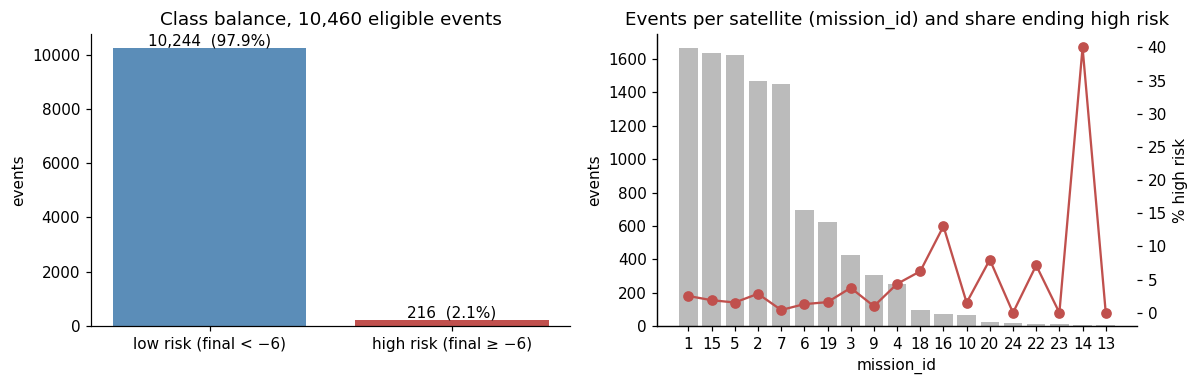

mission_id        1         15        5         2         7        6        19       3       9        4       18     16      10     20    24      22    23   14   13
events      1666.000  1639.000  1622.000  1469.000  1451.000  694.000  626.000  427.000  304.00  253.000  96.000  69.00  66.000  25.00  17.0  14.000  14.0  5.0  3.0
high_risk     42.000    31.000    25.000    42.000     6.000    9.000   10.000   16.000    3.00   11.000   6.000   9.00   1.000   2.00   0.0   1.000   0.0  2.0  0.0
rate           0.025     0.019     0.015     0.029     0.004    0.013    0.016    0.037    0.01    0.043   0.062   0.13   0.015   0.08   0.0   0.071   0.0  0.4  0.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
vc = events.high_risk.value_counts()
ax[0].bar(["low risk (final < −6)", "high risk (final ≥ −6)"], vc.values, color=["#5B8DB8", "#C0504D"])
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f"{v:,}  ({v / len(events):.1%})", ha="center", va="bottom")
ax[0].set_title("Class balance, 10,460 eligible events"); ax[0].set_ylabel("events")

m = events.groupby("mission_id").high_risk.agg(["size", "sum", "mean"]).sort_values("size", ascending=False)
ax[1].bar(m.index.astype(str), m["size"], color="#BBBBBB", label="events")
ax2 = ax[1].twinx(); ax2.plot(m.index.astype(str), 100 * m["mean"], "o-", color="#C0504D", label="% high risk")
ax[1].set_title("Events per satellite (mission_id) and share ending high risk"); ax[1].set_ylabel("events"); ax2.set_ylabel("% high risk")
ax[1].set_xlabel("mission_id"); fig.tight_layout(); plt.show()
print(m.rename(columns={"size": "events", "sum": "high_risk", "mean": "rate"}).round(3).T.to_string())

**Observations.** Only 216 of 10,460 events (2.1 %) end high risk, so accuracy is useless here: a model that never raises an alert is 97.9 % accurate. Five satellites account for three quarters of the events, and the high-risk rate differs by satellite: among the satellites with at least 50 events it runs from 0.4 % (mission 7, 1,451 events) to 13 % (mission 16, 69 events); the rates of the three smallest missions (3 to 14 events) mean nothing. A model could learn satellite-specific habits, so one of the robustness checks in Section 7 holds whole satellites out.

### 3.2 How the risk evolves: what the operator sees versus what happens

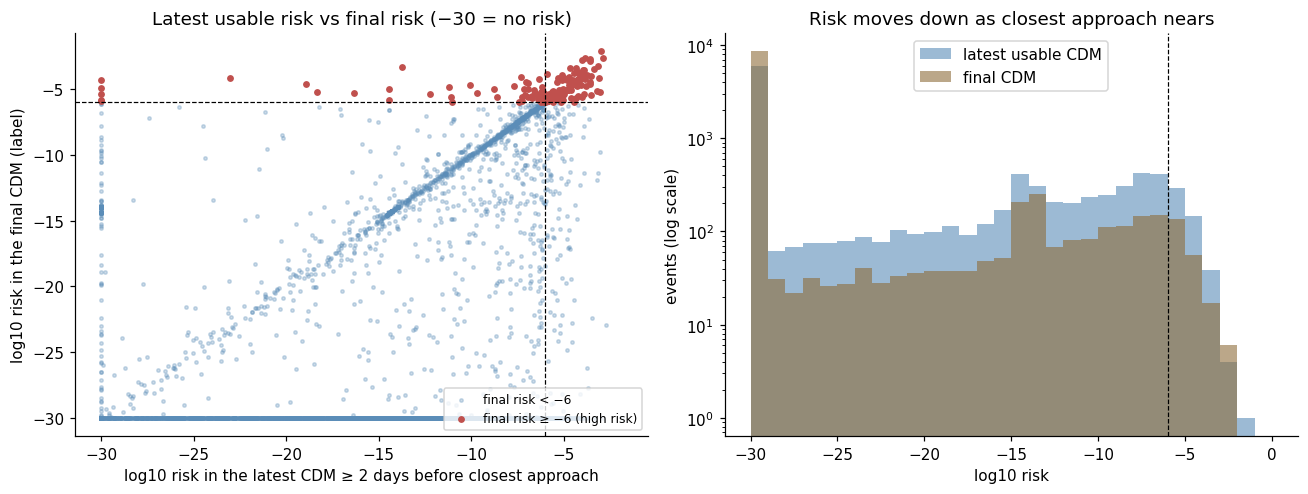

final risk vs latest usable risk:  lower 37.5%   unchanged 54.7%   higher 7.8%
naive forecast false alarms: 324 (of which 202 end at −30)
naive forecast misses: 54 (of which 26 had a latest risk between −7 and −6)


In [9]:
x = events.risk.clip(lower=-30); y = events.final_risk.clip(lower=-30); hi = events.high_risk == 1
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(x[~hi], y[~hi], s=5, alpha=0.3, color="#5B8DB8", label="final risk < −6")
ax[0].scatter(x[hi], y[hi], s=12, color="#C0504D", label="final risk ≥ −6 (high risk)")
ax[0].axvline(HIGH_RISK, color="k", ls="--", lw=0.8); ax[0].axhline(HIGH_RISK, color="k", ls="--", lw=0.8)
ax[0].set_xlabel("log10 risk in the latest CDM ≥ 2 days before closest approach"); ax[0].set_ylabel("log10 risk in the final CDM (label)")
ax[0].set_title("Latest usable risk vs final risk (−30 = no risk)"); ax[0].legend(loc="lower right", fontsize=8)
bins = np.linspace(-30, 0, 31)
ax[1].hist(x, bins=bins, alpha=0.6, label="latest usable CDM", color="#5B8DB8")
ax[1].hist(y, bins=bins, alpha=0.6, label="final CDM", color="#8E6C3A"); ax[1].set_yscale("log")
ax[1].axvline(HIGH_RISK, color="k", ls="--", lw=0.8); ax[1].set_xlabel("log10 risk"); ax[1].set_ylabel("events (log scale)")
ax[1].set_title("Risk moves down as closest approach nears"); ax[1].legend(); fig.tight_layout(); plt.show()

change = np.sign((events.final_risk - events.risk).round(6))
print("final risk vs latest usable risk:  lower {:.1%}   unchanged {:.1%}   higher {:.1%}".format(
    (change < 0).mean(), (change == 0).mean(), (change > 0).mean()))
fa = events[(events.lrp_high == 1) & (events.high_risk == 0)]; missed = events[(events.lrp_high == 0) & (events.high_risk == 1)]
print(f"naive forecast false alarms: {len(fa)} (of which {int((fa.final_risk <= -30).sum())} end at −30)")
print(f"naive forecast misses: {len(missed)} (of which {int(((missed.risk >= -7) & (missed.risk < -6)).sum())} had a latest risk between −7 and −6)")

**Observations.** Most events sit on the diagonal (the risk did not change) or drop to −30 (the approach was refined away). The naive forecast's 324 false alarms are mostly events whose risk collapsed in the last two days; half of its 54 misses had a latest risk *just* below −6, which suggests that a slightly lower alert threshold would catch them. The −30 "no risk" value is a code, not a measurement, and it dominates the distribution: 56 % of events have a latest risk of −30.

### 3.3 Message timing and the CDM series

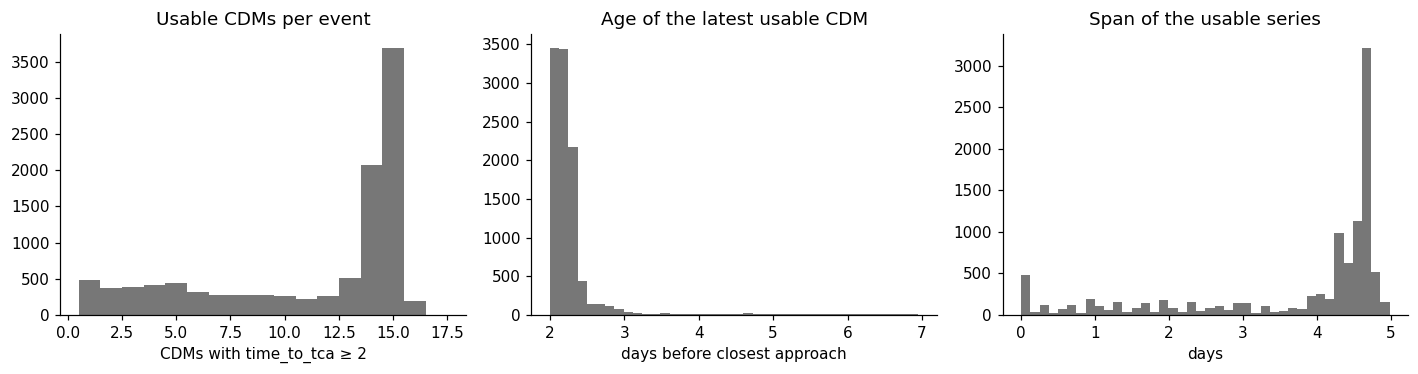

               count   mean   std  min   25%    50%    75%    max
n_cdms_used  10460.0  11.20  4.79  1.0  7.00  14.00  15.00  17.00
time_to_tca  10460.0   2.31  0.59  2.0  2.09   2.19   2.29   6.95
span_days    10460.0   3.68  1.48  0.0  2.99   4.42   4.66   4.99


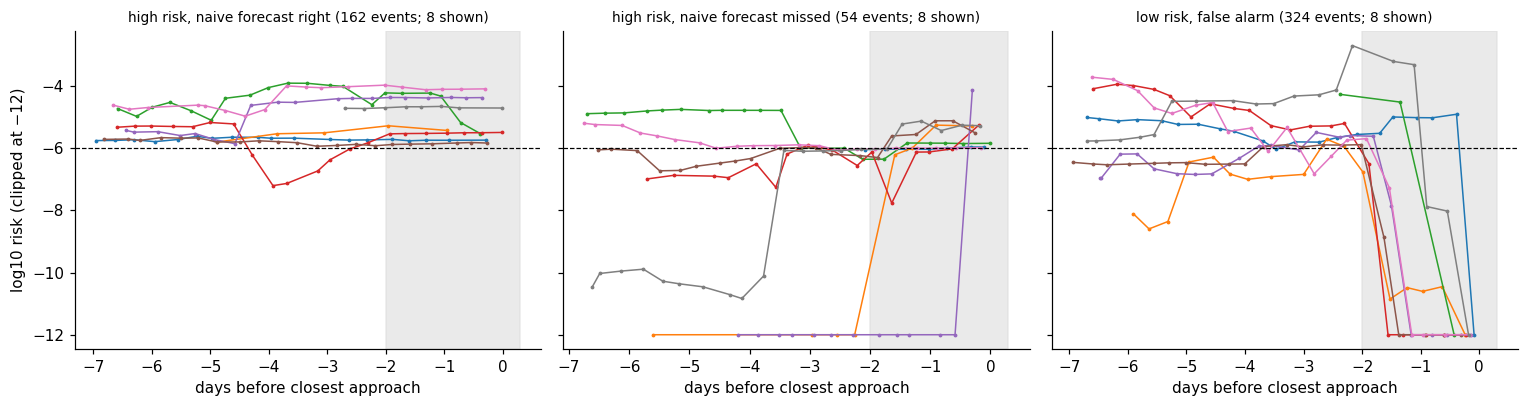

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(events.n_cdms_used, bins=np.arange(0.5, 18.5), color="#777")
ax[0].set_title("Usable CDMs per event"); ax[0].set_xlabel("CDMs with time_to_tca ≥ 2")
ax[1].hist(events.time_to_tca, bins=40, color="#777"); ax[1].set_title("Age of the latest usable CDM")
ax[1].set_xlabel("days before closest approach")
ax[2].hist(events.span_days, bins=40, color="#777"); ax[2].set_title("Span of the usable series"); ax[2].set_xlabel("days")
fig.tight_layout(); plt.show()
print(events[["n_cdms_used", "time_to_tca", "span_days"]].describe().round(2).T.to_string())

if raw is not None:
    # example series: risk over time for events the naive forecast gets right, misses, and false-alarms on
    r = raw[raw.event_id.isin(events.index)].copy(); r["risk"] = r.risk.clip(lower=-12)
    groups = {"high risk, naive forecast right": events[(events.lrp_high == 1) & (events.high_risk == 1)].index,
              "high risk, naive forecast missed": missed.index, "low risk, false alarm": fa.index}
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
    rng = np.random.default_rng(SEED)
    for a, (title, ids) in zip(ax, groups.items()):
        for e in rng.choice(ids, 8, replace=False):
            s = r[r.event_id == e].sort_values("time_to_tca", ascending=False)
            a.plot(-s.time_to_tca, s.risk, ".-", lw=1, ms=3)
        a.axvspan(-CUTOFF_DAYS, 0.3, color="#DDD", alpha=0.6); a.axhline(HIGH_RISK, color="k", ls="--", lw=0.8)
        a.set_title(f"{title} ({len(ids)} events; 8 shown)", fontsize=9); a.set_xlabel("days before closest approach")
    ax[0].set_ylabel("log10 risk (clipped at −12)"); fig.tight_layout(); plt.show()

**Observations.** The median event has 14 usable CDMs and the latest one is typically 2.1–2.3 days before closest approach, so the series is short and dense. In the example series (shown when the raw file is present) the grey band is the last two days the model never sees: the misses are events whose risk jumps up inside that band, often from "no risk", which no model can see coming from the earlier messages alone.

### 3.4 Which quantities relate to the outcome?

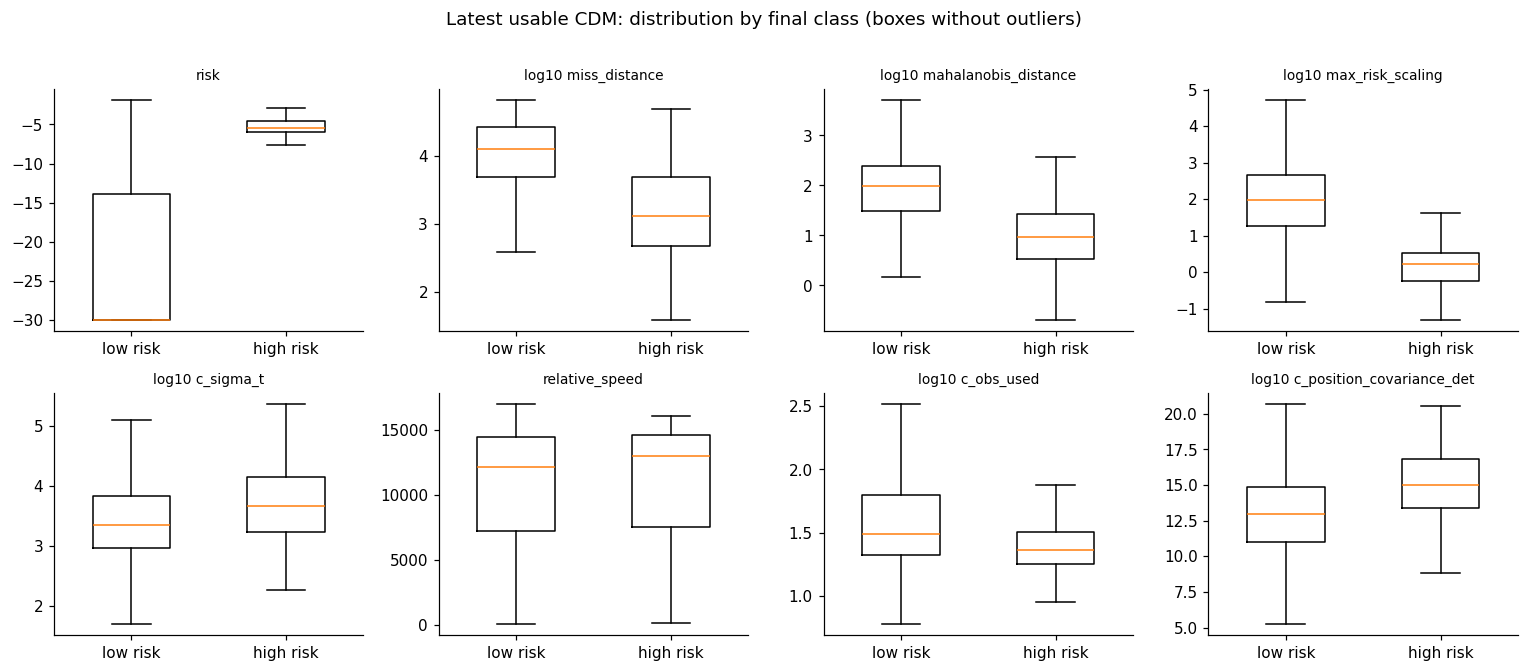

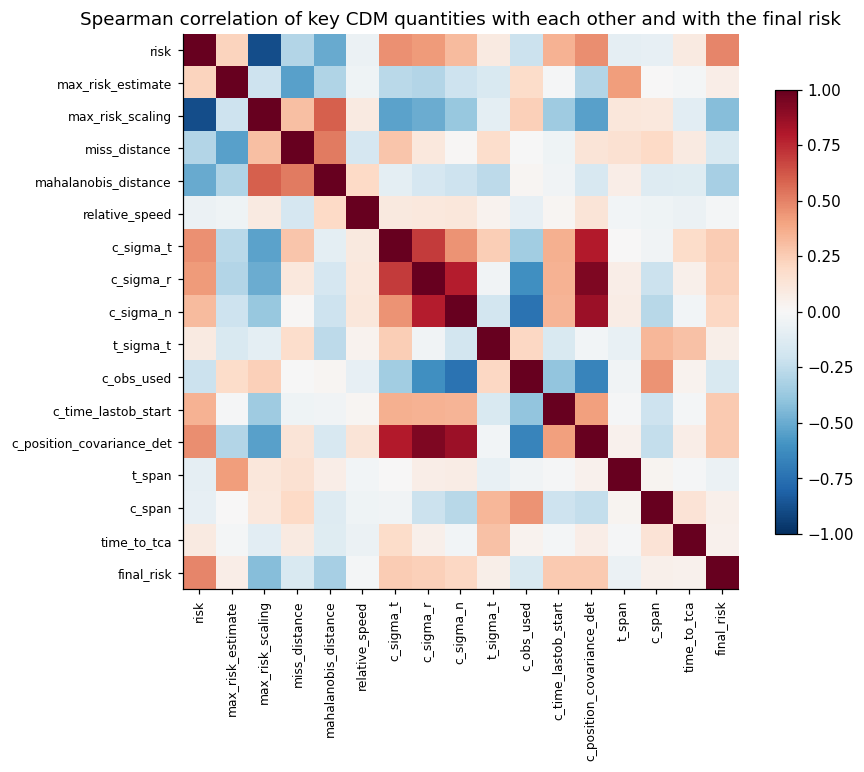

Spearman correlation with final_risk:
risk                         0.49
c_time_lastob_start          0.26
c_position_covariance_det    0.26
c_sigma_t                    0.25
c_sigma_r                    0.24
c_sigma_n                    0.21
max_risk_estimate            0.07
t_sigma_t                    0.06
c_span                       0.05
time_to_tca                  0.04
relative_speed              -0.02
t_span                      -0.06
miss_distance               -0.15
c_obs_used                  -0.15
mahalanobis_distance        -0.33
max_risk_scaling            -0.43


In [11]:
KEY = ["risk", "max_risk_estimate", "max_risk_scaling", "miss_distance", "mahalanobis_distance", "relative_speed",
       "c_sigma_t", "c_sigma_r", "c_sigma_n", "t_sigma_t", "c_obs_used", "c_time_lastob_start", "c_position_covariance_det",
       "t_span", "c_span", "time_to_tca"]
LOGPLOT = {"miss_distance", "mahalanobis_distance", "c_sigma_t", "c_sigma_r", "c_sigma_n", "t_sigma_t", "c_obs_used",
           "c_position_covariance_det", "max_risk_scaling"}
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for a, c in zip(axes.ravel(), ["risk", "miss_distance", "mahalanobis_distance", "max_risk_scaling", "c_sigma_t", "relative_speed", "c_obs_used", "c_position_covariance_det"]):
    lo = events.loc[events.high_risk == 0, c].dropna(); hi_ = events.loc[events.high_risk == 1, c].dropna()
    if c in LOGPLOT:
        lo, hi_ = np.log10(lo.clip(lower=1e-12)), np.log10(hi_.clip(lower=1e-12)); lab = f"log10 {c}"
    else:
        lo, hi_ = lo.clip(lower=-30), hi_.clip(lower=-30); lab = c
    a.boxplot([lo, hi_], widths=0.5, showfliers=False); a.set_xticks([1, 2]); a.set_xticklabels(["low risk", "high risk"])
    a.set_title(lab, fontsize=9)
fig.suptitle("Latest usable CDM: distribution by final class (boxes without outliers)", y=1.01); fig.tight_layout(); plt.show()

corr = events[KEY + ["final_risk"]].copy()
for c in LOGPLOT: corr[c] = np.log10(corr[c].clip(lower=1e-12))
corr = corr.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
plt.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Spearman correlation of key CDM quantities with each other and with the final risk")
fig.tight_layout(); plt.show()
print("Spearman correlation with final_risk:")
print(corr["final_risk"].drop("final_risk").sort_values(ascending=False).round(2).to_string())

**Observations.** The latest `risk` is the quantity most related to the outcome (Spearman 0.49 with the final risk; the box plot shows the high-risk events almost all have a latest risk above −8 while the low-risk median is −30). Next come `max_risk_scaling` (−0.43: a small scaling factor means the reported risk is close to the maximum possible) and the Mahalanobis distance (−0.33) and miss distance (−0.15), both smaller for high-risk events, and the chaser's position uncertainties `c_sigma_t/r/n`, covariance determinant and time since its last observation `c_time_lastob_start` (+0.21 to +0.26: a poorly or recently tracked object leaves more room for a dangerous outcome); the number of observations `c_obs_used` shifts less (−0.15). Many columns are heavily right-skewed and span orders of magnitude, so they will be log-transformed before scaling.

**Features worth engineering (carried into Section 4).**

1. Summaries of the *history* of each event, not just its latest message: the first value, mean, minimum, maximum, standard deviation, total change and trend (slope) of `risk`, `miss_distance`, `mahalanobis_distance`, `max_risk_estimate`, the chaser sigmas, `t_sigma_t` and `c_obs_used`, plus the number of usable CDMs, the time span covered and the largest jump in risk.
2. Log transforms for the skewed, non-negative physical quantities (distances, sigmas, counts).
3. Missing indicators for the columns whose absence is informative.
4. A feature set *without* any risk column, to measure how much the other physics knows on its own.

## 4. Feature engineering

### 4.1 Engineered features

`build_table.py` already computed the history features when it built the event table, because they must be computed from the usable CDMs only (a safeguard against leakage). For each of nine base quantities it adds seven statistics over the usable series: `_first`, `_mean`, `_min`, `_max`, `_std`, `_change` (latest − first) and `_slope` (least-squares trend per day towards closest approach), plus `n_cdms_used`, `span_days` and `risk_max_jump`: 9 × 7 + 3 = **66 engineered features**. The table below shows a few of them for the first events.

In [12]:
HIST_BASES = ["risk", "miss_distance", "mahalanobis_distance", "max_risk_estimate", "c_sigma_t", "c_sigma_r", "c_sigma_n", "t_sigma_t", "c_obs_used"]
HIST_SUFFIX = ("_first", "_mean", "_min", "_max", "_std", "_change", "_slope")
HIST_EXTRA = ["n_cdms_used", "span_days", "risk_max_jump"]
hist_cols = [b + s for b in HIST_BASES for s in HIST_SUFFIX] + HIST_EXTRA
assert all(c in events.columns for c in hist_cols) and len(hist_cols) == 66
display(events[["risk", "risk_first", "risk_mean", "risk_max", "risk_change", "risk_slope", "risk_max_jump", "n_cdms_used", "span_days"]].head(6).round(3))

# The same features recomputed here from the raw messages for 300 random events, to show the code and check it.
def slope(t, y):
    # least-squares slope per day towards closest approach (positive = rising as TCA nears)
    if len(t) < 2: return np.nan
    x = -np.asarray(t, float); x = x - x.mean(); d = (x * x).sum()
    return float((x * (np.asarray(y, float) - np.asarray(y, float).mean())).sum() / d) if d > 0 else np.nan

if raw is not None:
    sample = np.random.default_rng(SEED).choice(events.index.values, 300, replace=False)
    use = raw[(raw.time_to_tca >= CUTOFF_DAYS) & raw.event_id.isin(sample)].sort_values(["event_id", "time_to_tca"], ascending=[True, False])
    gu = use.groupby("event_id")
    recomputed = pd.DataFrame({"risk_first": gu.risk.first(), "risk_mean": gu.risk.mean(), "risk_min": gu.risk.min(), "risk_max": gu.risk.max(),
                               "risk_std": gu.risk.std().fillna(0.0), "risk_change": gu.risk.last() - gu.risk.first(),
                               "risk_slope": gu.apply(lambda d: slope(d.time_to_tca.values, d.risk.values)),
                               "risk_max_jump": gu.risk.apply(lambda v: float(np.abs(np.diff(v.values)).max()) if len(v) > 1 else 0.0),
                               "n_cdms_used": gu.size(), "span_days": gu.time_to_tca.max() - gu.time_to_tca.min()})
    stored = events.loc[recomputed.index, recomputed.columns]
    diff = (recomputed - stored).abs().fillna(0).max().max()
    print(f"history features recomputed from the raw CDMs for {len(recomputed)} events: largest difference from the stored table = {diff:.2e}")
    assert diff < 1e-6

# the three feature sets compared in this project
latest_cols = [c for c in events.columns if c not in NOT_FEATURES and c not in hist_cols]
history_cols = latest_cols + hist_cols
RISK_BASES = {"risk", "max_risk_estimate", "max_risk_scaling"}
def base_name(c):
    if c == "risk_max_jump": return "risk"
    for s in HIST_SUFFIX:
        if c.endswith(s): return c[:-len(s)]
    return c
no_risk_cols = [c for c in history_cols if base_name(c) not in RISK_BASES]
FEATURE_SETS = {"latest": latest_cols, "history": history_cols, "no_risk": no_risk_cols}
for k, v in FEATURE_SETS.items():
    print(f"{k:8s} {len(v)} columns ({len([c for c in v if c in CATEGORICAL])} categorical)")

,risk,risk_first,risk_mean,risk_max,risk_change,risk_slope,risk_max_jump,n_cdms_used,span_days
event_id,,,,,,,,,
3,-30.000,-10.816,-27.262,-10.816,-19.184,-2.857,19.150,14,4.643
4,-7.332,-7.297,-7.312,-7.282,-0.035,-0.007,0.034,5,4.613
5,-30.000,-9.568,-20.422,-9.412,-20.432,-6.181,20.476,15,4.671
7,-30.000,-7.871,-15.280,-7.871,-22.129,-11.705,22.031,3,1.900
8,-13.100,-6.190,-5.827,-4.050,-6.910,-0.514,8.095,14,4.686
9,-30.000,-12.157,-23.915,-12.157,-17.843,-4.690,10.574,15,4.694


history features recomputed from the raw CDMs for 300 events: largest difference from the stored table = 3.55e-15
latest   101 columns (1 categorical)
history  167 columns (1 categorical)
no_risk  149 columns (1 categorical)


### 4.2 Scaling, transformation and encoding

All preprocessing lives in a scikit-learn `ColumnTransformer` that is fitted on the **training rows only**:

* numeric columns: median imputation + missing indicator, then standardisation (zero mean, unit variance), which logistic regression, the SVM and the network need;
* skewed non-negative columns (skewness > 2 on the training data): `log1p` before the same imputation and scaling;
* `c_object_type`: one-hot encoding (rare categories grouped, unknown categories ignored).

Which columns get the log transform is decided from the training features alone. Below the preprocessor is built, fitted on the training split of Section 2.6, and the feature-engineered matrices are saved as the **feature-engineered dataset** (`data/processed/features_train.csv.gz`, `features_test.csv.gz`).

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer

def skewed_columns(X, num):
    out = []
    for c in num:
        x = X[c].dropna()
        if len(x) > 10 and x.min() >= 0 and x.skew() > 2:
            out.append(c)
    return out

def make_preprocessor(X_train, cols):
    cat = [c for c in cols if c in CATEGORICAL]; num = [c for c in cols if c not in cat]
    log_cols = skewed_columns(X_train, num); lin = [c for c in num if c not in log_cols]
    steps = lambda: [("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]
    parts = [("num", Pipeline(steps()), lin),
             ("log", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))] + steps()), log_cols)]
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat))
    return ColumnTransformer(parts, sparse_threshold=0), log_cols

# --- the split from Section 2.6
X_all = events[history_cols]
X_train, X_test = X_all.iloc[idx_train], X_all.iloc[idx_test]

pre, log_cols = make_preprocessor(X_train, history_cols)
Xt_train = pre.fit_transform(X_train); Xt_test = pre.transform(X_test)
feat_names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
print(f"\n{len(history_cols)} input columns -> {Xt_train.shape[1]} model inputs "
      f"({len(log_cols)} log-transformed, {sum('missingindicator' in n for n in feat_names)} missing indicators, "
      f"{sum(n.startswith('c_object_type') for n in feat_names)} one-hot columns)")
print("log-transformed columns:", ", ".join(log_cols[:12]), "...")
pd.DataFrame(Xt_train, index=X_train.index, columns=feat_names).round(4).to_csv(os.path.join(PROC, "features_train.csv.gz"))
pd.DataFrame(Xt_test, index=X_test.index, columns=feat_names).round(4).to_csv(os.path.join(PROC, "features_test.csv.gz"))
print("saved data/processed/features_train.csv.gz and features_test.csv.gz")
pd.DataFrame(Xt_train[:5, :8], columns=feat_names[:8]).round(3)


167 input columns -> 216 model inputs (64 log-transformed, 45 missing indicators, 5 one-hot columns)
log-transformed columns: time_to_tca, max_risk_scaling, t_time_lastob_start, t_time_lastob_end, t_rcs_estimate, t_cr_area_over_mass, t_j2k_ecc, c_recommended_od_span, c_obs_available, c_obs_used, c_rcs_estimate, c_j2k_sma ...


saved data/processed/features_train.csv.gz and features_test.csv.gz


,risk,max_risk_estimate,miss_distance,relative_speed,relative_position_r,relative_position_t,relative_position_n,relative_velocity_r
0,-0.784,1.093,-1.099,0.027,0.489,-0.034,-0.014,-0.133
1,1.110,2.339,-0.962,-1.995,-0.105,0.145,0.022,-0.043
2,-0.784,-0.782,1.829,0.046,-1.606,-1.948,-1.979,0.279
3,-0.784,1.703,-1.061,0.634,0.331,-0.043,-0.055,-0.028
4,1.353,1.491,-1.016,0.717,-0.004,0.029,-0.098,0.085


### 4.3 Feature selection and rationale

Rather than filter columns by a univariate statistic (which with 216 positives would be noisy), the project keeps every physical column and compares **three feature sets** as an experiment: the latest CDM alone (100 numeric + 1 categorical), the latest CDM plus the 66 history summaries, and the history set without any risk-derived column. Section 7.3 reports what each set achieves, and Section 7.4 runs an explicit selection experiment: the 20 columns that matter most to the final model (permutation importance measured on training rows only) are kept and the models are refitted on them alone. No interaction terms were created by hand: the tree-based models and the network learn interactions themselves, and logistic regression on the scaled inputs is kept as the interpretable linear reference.

## 5. Model building and hyperparameter optimisation

### 5.1 Split, baselines and models

**Split.** Stratified 80/20 split of the 10,460 eligible events (seed 465): 8,368 training events with 173 high-risk, 2,092 test events with 43 high-risk. The test events are touched only in Section 6. (ESA's own competition split and a 25-fold cross-validation are used in Section 7 as further checks.)

**Baselines.** The naive forecast (latest usable risk, decided at −6), the same score with a threshold chosen by cross-validation, and a constant score. A **shuffled-label control** (models trained on permuted labels) shows what "no signal" looks like.

**Models.** The four course models with balanced class weights, plus gradient boosting as the strongest tabular learner:

| model | course reference | what is tuned |
|---|---|---|
| Logistic regression | linear classification with the sigmoid, regularised | inverse regularisation strength C |
| Decision tree | tree learning with class weights | maximum depth, minimum rows per leaf |
| Neural network (TensorFlow/Keras) | dense layers with ReLU, sigmoid output, Adam, early stopping | hidden layer sizes, learning rate |
| SVM (RBF kernel) | large-margin classifier with a kernel | C, kernel width γ |
| Gradient boosting (histogram GBDT) | ensemble of shallow trees | learning rate, leaves per tree |

Each model is wrapped in a `Pipeline` with the preprocessor from Section 4, so that imputation statistics, scaling and the log columns are recomputed inside every cross-validation fold.

In [14]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             confusion_matrix, f1_score, brier_score_loss)

class KerasNet(BaseEstimator, ClassifierMixin):
    # Dense network in the course's TensorFlow style. Two-stage protocol: hold out 15 % of the training rows
    # to find the best epoch by early stopping, then retrain on all the training rows for that many epochs.
    def __init__(self, units=(64, 32), lr=1e-3, seed=SEED, max_epochs=150, patience=10, two_stage=True):
        self.units, self.lr, self.seed, self.max_epochs, self.patience, self.two_stage = units, lr, seed, max_epochs, patience, two_stage
    def _build(self, n_in):
        import tensorflow as tf
        from tensorflow.keras.models import Sequential
        from tensorflow.keras.layers import Dense, Input
        try:                                   # repeatable training run to run
            tf.config.experimental.enable_op_determinism()
        except Exception:
            pass
        tf.keras.utils.set_random_seed(self.seed)
        layers = [Input(shape=(n_in,))] + [Dense(units=u, activation="relu") for u in self.units] + [Dense(units=1, activation="sigmoid")]
        m = Sequential(layers)
        m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=self.lr), loss="binary_crossentropy")
        return m
    def fit(self, X, y):
        import tensorflow as tf
        X = np.asarray(X, np.float32); y = np.asarray(y, np.float32); self.classes_ = np.array([0, 1])
        pos = y.mean(); cw = {0: 0.5 / (1 - pos), 1: 0.5 / pos}
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.15, stratify=y, random_state=self.seed)
        m = self._build(X.shape[1])
        es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=self.patience, restore_best_weights=True)
        h = m.fit(Xa, ya, validation_data=(Xb, yb), epochs=self.max_epochs, batch_size=128, class_weight=cw, callbacks=[es], verbose=0)
        self.best_epoch_ = int(np.argmin(h.history["val_loss"])) + 1
        if self.two_stage:
            self.model_ = self._build(X.shape[1]); self.model_.fit(X, y, epochs=self.best_epoch_, batch_size=128, class_weight=cw, verbose=0)
        else:
            self.model_ = m
        tf.keras.backend.clear_session(); return self
    def predict_proba(self, X):
        p = self.model_.predict(np.asarray(X, np.float32), verbose=0).ravel(); return np.c_[1 - p, p]
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def make_model(name, **p):
    if name == "logreg": return LogisticRegression(class_weight="balanced", max_iter=5000, **p)
    if name == "tree":   return DecisionTreeClassifier(class_weight="balanced", random_state=SEED, **p)
    if name == "svm":    return SVC(kernel="rbf", class_weight="balanced", random_state=SEED, **p)
    if name == "nn":     return KerasNet(seed=SEED, **p)
    if name == "hgb":    return HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED, min_samples_leaf=20,
                                                               l2_regularization=1.0, max_iter=150, **p)
    raise ValueError(name)

LABEL = {"logreg": "Logistic regression", "tree": "Decision tree", "nn": "Neural network", "svm": "SVM (RBF)",
         "hgb": "Gradient boosting", "lrp": "Naive forecast (latest risk at −6)", "lrp_tuned": "Naive forecast, tuned threshold",
         "constant": "Constant score", "control": "Shuffled-label control"}

def score_of(pipe, X):
    est = pipe[-1]
    return pipe.predict_proba(X)[:, 1] if hasattr(est, "predict_proba") else pipe.decision_function(X)

### 5.2 Hyperparameter optimisation by cross-validation

For each model, every combination in a small grid is scored by **3-fold stratified cross-validation on the training split** (the test split is never used), with **average precision (PR-AUC)** as the selection score: it measures the quality of the whole ranking of events on an imbalanced problem, without depending on a threshold. The grids are deliberately modest and bracket the usual defaults, because the training data contains only 173 high-risk events (about 58 per inner fold), so large grids would overfit the validation folds.

Rationale for each grid:

* **Logistic regression, C ∈ {0.01, 0.1, 1, 10}:** from strong to weak L2 regularisation on the 216 standardised inputs.
* **Decision tree, depth ∈ {3, 6, 10} × min rows per leaf ∈ {5, 25, 100}:** controls over-fitting of a single tree.
* **Neural network, hidden layers ∈ {(32), (64, 32), (128, 64)} × learning rate ∈ {1e-3, 1e-2}:** capacity and step size; the number of epochs is set by early stopping inside each fit (patience 10), so it is not in the grid.
* **SVM, C ∈ {0.3, 1, 3} × γ ∈ {scale, 0.001, 0.01}:** margin softness and kernel width (`scale` = 1/(n_features·var) ≈ 0.005 here; a smaller γ is a wider, smoother kernel).
* **Gradient boosting, learning rate ∈ {0.05, 0.1} × leaves per tree ∈ {7, 15, 31}:** shrinkage and tree size, with 150 trees and L2 = 1 fixed.

During the search the network is scored as the early-stopped net of each fold (one training pass); the final fit in 5.3 uses the two-stage protocol (find the epoch, retrain on everything). Every (model, combination) result is cached, so the search can be interrupted and resumed.

In [15]:
GRIDS = {
    "logreg": {"C": [0.01, 0.1, 1.0, 10.0]},
    "tree":   {"max_depth": [3, 6, 10], "min_samples_leaf": [5, 25, 100]},
    "nn":     {"units": [(32,), (64, 32), (128, 64)], "lr": [1e-3, 1e-2]},
    "svm":    {"C": [0.3, 1.0, 3.0], "gamma": ["scale", 0.001, 0.01]},
    "hgb":    {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [7, 15, 31]},
}
INNER = StratifiedKFold(3, shuffle=True, random_state=SEED)
inner_folds = list(INNER.split(X_train, y_train))

def combos(grid):
    keys = list(grid)
    for vals in itertools.product(*[grid[k] for k in keys]):
        yield dict(zip(keys, vals))

def cv_average_precision(name, params):
    # mean PR-AUC over the inner folds; the preprocessor is refitted inside each fold
    scores = []
    for a, b in inner_folds:
        est = make_model(name, **params)
        if name == "nn": est.set_params(two_stage=False)   # keep the early-stopped net during the search (faster)
        pipe = Pipeline([("pre", make_preprocessor(X_train.iloc[a], history_cols)[0]), ("clf", est)])
        pipe.fit(X_train.iloc[a], y_train[a])
        scores.append(float(average_precision_score(y_train[b], score_of(pipe, X_train.iloc[b]))))
    return scores

search = {}
t0 = time.time()
for name, grid in GRIDS.items():
    cache_p = os.path.join(CACHE, f"search_{name}.json")
    done = json.load(open(cache_p)) if os.path.exists(cache_p) else {}
    for params in combos(grid):
        key = json.dumps(params)
        if key not in done:
            check_budget()
            done[key] = cv_average_precision(name, params)
            json.dump(done, open(cache_p, "w"), indent=1)
    search[name] = done
print(f"search complete ({time.time() - t0:.0f} s this run; cached results reused where available)")

rows = []
for name, done in search.items():
    for key, sc in done.items():
        rows.append({"model": LABEL[name], "params": key, "cv PR-AUC": np.mean(sc), "sd": np.std(sc)})
search_df = pd.DataFrame(rows)
best_params = {}
for name, done in search.items():
    key = max(done, key=lambda k: np.mean(done[k])); best_params[name] = json.loads(key)
    if name == "nn": best_params[name]["units"] = tuple(best_params[name]["units"])
print("\nBest combination per model (inner-CV PR-AUC):")
for name in GRIDS:
    key = json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in best_params[name].items()})
    print(f"  {LABEL[name]:20s} {best_params[name]}   PR-AUC {np.mean(search[name][key]):.3f} ± {np.std(search[name][key]):.3f}")
json.dump({k: {kk: (list(vv) if isinstance(vv, tuple) else vv) for kk, vv in v.items()} for k, v in best_params.items()},
          open(os.path.join(OUT, "tuned_params.json"), "w"), indent=1)

search complete (0 s this run; cached results reused where available)

Best combination per model (inner-CV PR-AUC):
  Logistic regression  {'C': 0.01}   PR-AUC 0.302 ± 0.018
  Decision tree        {'max_depth': 6, 'min_samples_leaf': 100}   PR-AUC 0.376 ± 0.055
  Neural network       {'units': (64, 32), 'lr': 0.001}   PR-AUC 0.320 ± 0.043
  SVM (RBF)            {'C': 0.3, 'gamma': 0.001}   PR-AUC 0.353 ± 0.041
  Gradient boosting    {'learning_rate': 0.05, 'max_leaf_nodes': 7}   PR-AUC 0.417 ± 0.034


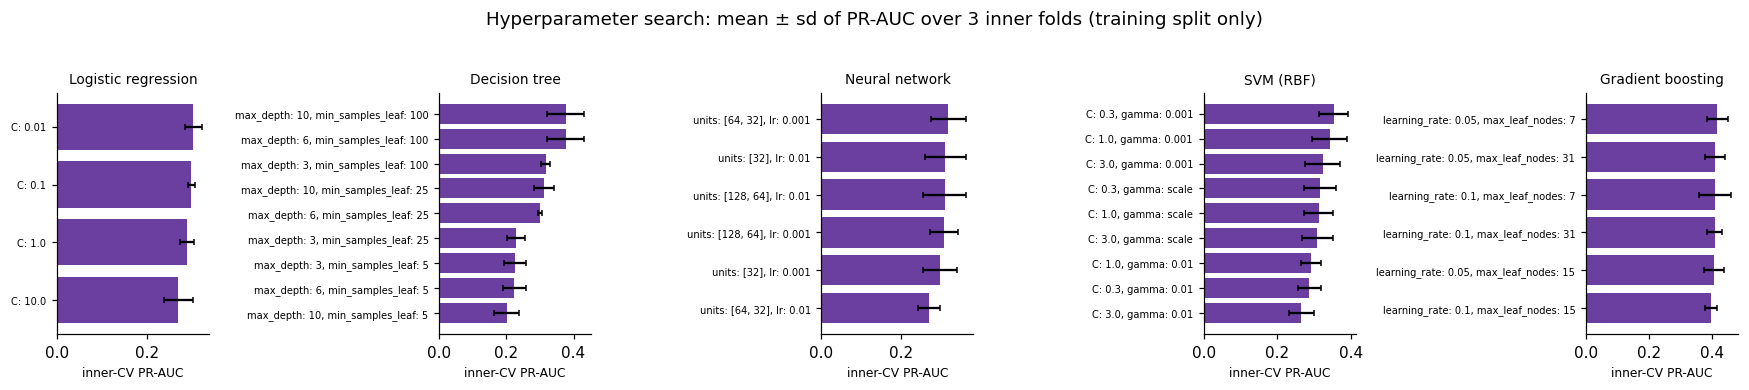

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, name in zip(axes, GRIDS):
    d = search_df[search_df.model == LABEL[name]].sort_values("cv PR-AUC")
    labels = [k.replace('"', "").replace("{", "").replace("}", "") for k in d.params]
    ax.barh(range(len(d)), d["cv PR-AUC"], xerr=d["sd"], color="#6B3FA0", capsize=2)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(labels, fontsize=6.5); ax.set_title(LABEL[name], fontsize=9); ax.set_xlabel("inner-CV PR-AUC", fontsize=8)
fig.suptitle("Hyperparameter search: mean ± sd of PR-AUC over 3 inner folds (training split only)", y=1.03); fig.tight_layout(); plt.show()

### 5.3 Final training, and the alert threshold

With the chosen hyperparameters (for the tree, depth 6 and depth 10 tie exactly at 100 rows per leaf, and the shallower tree is kept), each model is refitted on the **whole training split**. A classifier's score has to be turned into an alert decision; the threshold is chosen to **maximise F2 on out-of-fold predictions of the training split** (3-fold `cross_val_predict`), never on the test set. F2 weights recall four times as much as precision, which is ESA's metric: a missed collision costs far more than an unnecessary manoeuvre. The naive forecast gets the same treatment ("tuned threshold") so the comparison is fair.

In [17]:
def best_f2_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f2 = 5 * p[:-1] * r[:-1] / np.maximum(4 * p[:-1] + r[:-1], 1e-12)
    return float(t[int(np.argmax(f2))])

def fit_final(name, params, Xtr, ytr, Xte, cols=history_cols, tag=""):
    # returns test scores + the threshold chosen on the training split (cached)
    cache_p = os.path.join(CACHE, f"final_{name}{tag}.npz")
    if os.path.exists(cache_p):
        z = np.load(cache_p); return z["scores"], float(z["threshold"]), json.loads(str(z["info"]))
    check_budget()
    pre_, _ = make_preprocessor(Xtr, cols)
    pipe = Pipeline([("pre", pre_), ("clf", make_model(name, **params))])
    method = "predict_proba" if name != "svm" else "decision_function"
    inner_pipe = clone(pipe)
    if name == "nn": inner_pipe.set_params(clf__two_stage=False)
    oof = cross_val_predict(inner_pipe, Xtr, ytr, cv=INNER, method=method)
    oof = oof[:, 1] if oof.ndim == 2 else oof
    thr = best_f2_threshold(ytr, oof)
    t0 = time.time(); pipe.fit(Xtr, ytr); fit_s = time.time() - t0
    scores = score_of(pipe, Xte)
    info = {"fit_seconds": round(fit_s, 1), "train_oof_ap": float(average_precision_score(ytr, oof))}
    if name == "nn": info["best_epoch"] = int(pipe[-1].best_epoch_)
    np.savez(cache_p, scores=scores, threshold=thr, info=json.dumps(info))
    return scores, thr, info

MODELS = ["logreg", "tree", "nn", "svm", "hgb"]
test_scores, thresholds, fit_info = {}, {}, {}
for name in MODELS:
    test_scores[name], thresholds[name], fit_info[name] = fit_final(name, best_params[name], X_train, y_train, X_test)
    print(f"{LABEL[name]:20s} threshold {thresholds[name]:7.3f}   fit {fit_info[name]['fit_seconds']:6.1f} s   {'epochs ' + str(fit_info[name]['best_epoch']) if name == 'nn' else ''}")

# baselines on the same test split
test_scores["lrp"] = risk_test; thresholds["lrp"] = HIGH_RISK
test_scores["lrp_tuned"] = risk_test; thresholds["lrp_tuned"] = best_f2_threshold(y_train, risk_train)
test_scores["constant"] = np.full(len(y_test), y_train.mean()); thresholds["constant"] = 0.0
print(f"\nnaive forecast threshold tuned on the training split: {thresholds['lrp_tuned']:.3f}")

# shuffled-label control: logistic regression and boosting trained on permuted labels (3 permutations each)
def control_scores():
    check_budget(); rng = np.random.default_rng(SEED); out = {}
    for j in range(3):
        yp = rng.permutation(y_train)
        for name in ("logreg", "hgb"):
            pipe = Pipeline([("pre", make_preprocessor(X_train, history_cols)[0]), ("clf", make_model(name, **best_params[name]))]).fit(X_train, yp)
            out[f"{name}_{j}"] = score_of(pipe, X_test).tolist()
    return out
ctrl = cached_json("control_scores", control_scores)
print("shuffled-label controls trained:", len(ctrl))

Logistic regression  threshold   0.794   fit    0.9 s   
Decision tree        threshold   0.909   fit    0.6 s   
Neural network       threshold   0.098   fit    4.6 s   epochs 23
SVM (RBF)            threshold   0.524   fit    2.0 s   


Gradient boosting    threshold   0.730   fit    0.6 s   

naive forecast threshold tuned on the training split: -6.052
shuffled-label controls trained: 6


## 6. Model evaluation and comparison

### 6.1 Metrics

For every model on the 2,092 held-out test events (43 high risk): **accuracy**, **precision**, **recall**, **F1**, **F2** at the model's own threshold; **PR-AUC** (average precision) and **ROC-AUC** for the ranking independent of any threshold; the **Brier score** for the probabilistic models; and, to compare rankings at the same operating point, **F2 when the model is allowed exactly as many alerts as the naive forecast raises**. Accuracy is reported because the rubric asks for it, with the reminder that "never alert" scores 97.9 %.

In [18]:
def f2_top_k(y, s, k):
    order = np.argsort(-np.asarray(s), kind="stable"); pred = np.zeros(len(y), int); pred[order[:k]] = 1
    return float(fbeta_score(y, pred, beta=2))

def evaluate(y, s, thr, proba=True, n_flag=None):
    pred = (np.asarray(s) >= thr).astype(int)
    tn, fp, fn, tp = [int(v) for v in confusion_matrix(y, pred, labels=[0, 1]).ravel()]
    out = {"accuracy": float(accuracy_score(y, pred)), "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
           "F1": float(f1_score(y, pred)), "F2": float(fbeta_score(y, pred, beta=2)),
           "PR-AUC": float(average_precision_score(y, s)), "ROC-AUC": float(roc_auc_score(y, s)),
           "TP": tp, "FP": fp, "FN": fn, "TN": tn}
    if proba: out["Brier"] = float(brier_score_loss(y, np.clip(s, 0, 1)))
    if n_flag is not None: out["F2 at naive alert count"] = f2_top_k(y, s, n_flag)
    return out

n_flag = int((risk_test >= HIGH_RISK).sum())
ORDER = ["lrp", "lrp_tuned", "logreg", "tree", "nn", "svm", "hgb", "constant"]
results = {}
for name in ORDER:
    proba = name in ("logreg", "tree", "nn", "hgb")
    results[name] = evaluate(y_test, test_scores[name], thresholds[name], proba=proba, n_flag=n_flag)
ctrl_m = pd.DataFrame([evaluate(y_test, np.array(v), best_f2_threshold(y_test, np.array(v))) for v in ctrl.values()])
results["control"] = {k: ctrl_m[k].mean() for k in ("PR-AUC", "ROC-AUC")}   # a control has no meaningful threshold
results["control"].update({k: np.nan for k in ("accuracy", "precision", "recall", "F1", "F2", "Brier", "F2 at naive alert count")})
res_df = pd.DataFrame(results).T.rename(index=LABEL)
cols = ["accuracy", "precision", "recall", "F1", "F2", "F2 at naive alert count", "PR-AUC", "ROC-AUC", "Brier", "TP", "FP", "FN"]
print(f"Test split: {len(y_test):,} events, {int(y_test.sum())} high risk; the naive forecast raises {n_flag} alerts")
display(res_df[cols].astype(float).round(3))
res_df.to_csv(os.path.join(OUT, "notebook_test_metrics.csv"))

Test split: 2,092 events, 43 high risk; the naive forecast raises 111 alerts


,accuracy,precision,recall,F1,F2,F2 at naive alert count,PR-AUC,ROC-AUC,Brier,TP,FP,FN
Naive forecast (latest risk at −6),0.961,0.324,0.837,0.468,0.636,0.636,0.431,0.967,NaN,36.0,75.0,7.0
"Naive forecast, tuned threshold",0.960,0.322,0.860,0.468,0.645,0.636,0.431,0.967,NaN,37.0,78.0,6.0
Logistic regression,0.950,0.242,0.674,0.356,0.497,0.512,0.383,0.958,0.082,29.0,91.0,14.0
Decision tree,0.974,0.389,0.488,0.433,0.465,0.601,0.376,0.942,0.069,21.0,33.0,22.0
Neural network,0.957,0.247,0.535,0.338,0.434,0.477,0.316,0.955,0.025,23.0,70.0,20.0
SVM (RBF),0.934,0.211,0.814,0.335,0.518,0.495,0.470,0.965,NaN,35.0,131.0,8.0
Gradient boosting,0.967,0.348,0.721,0.470,0.594,0.601,0.444,0.974,0.036,31.0,58.0,12.0
Constant score,0.021,0.021,1.000,0.040,0.095,0.053,0.021,0.500,NaN,43.0,2049.0,0.0
Shuffled-label control,NaN,NaN,NaN,NaN,NaN,NaN,0.018,0.417,NaN,NaN,NaN,NaN


### 6.2 Confusion matrices, PR and ROC curves

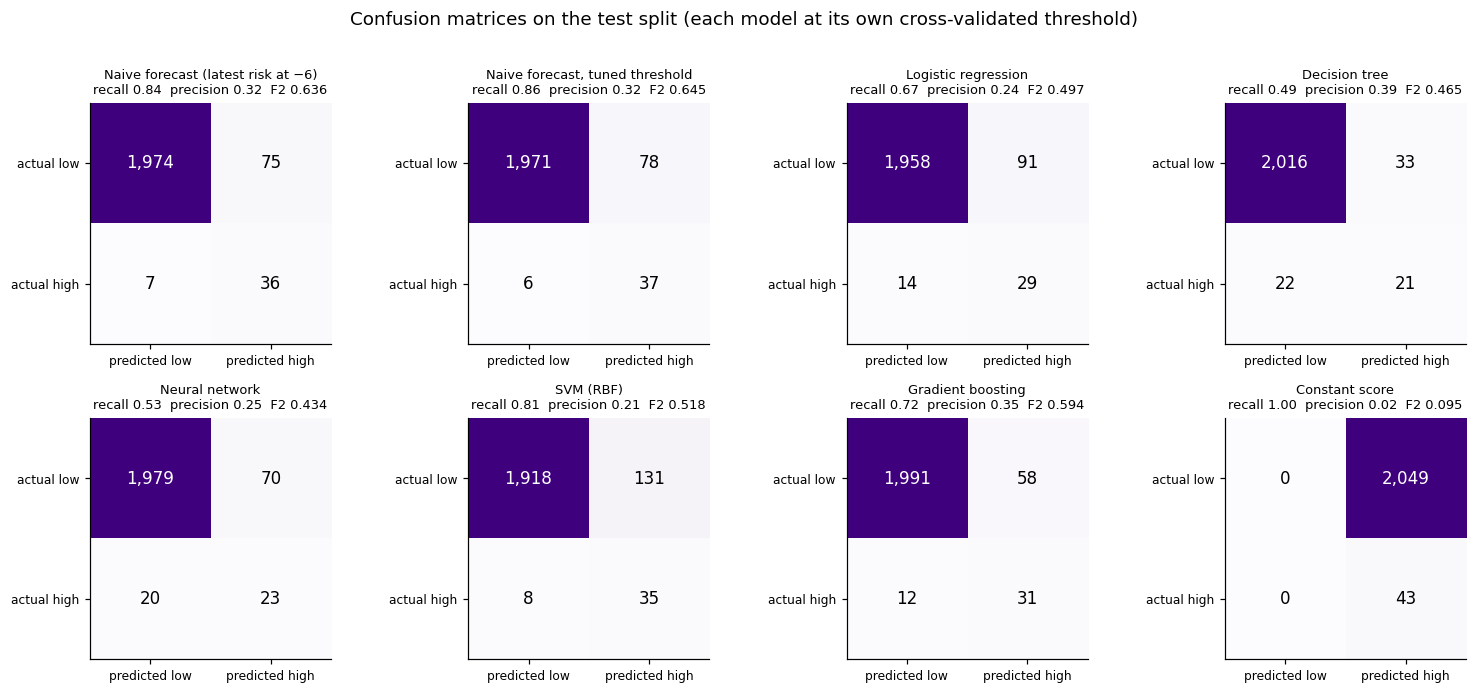

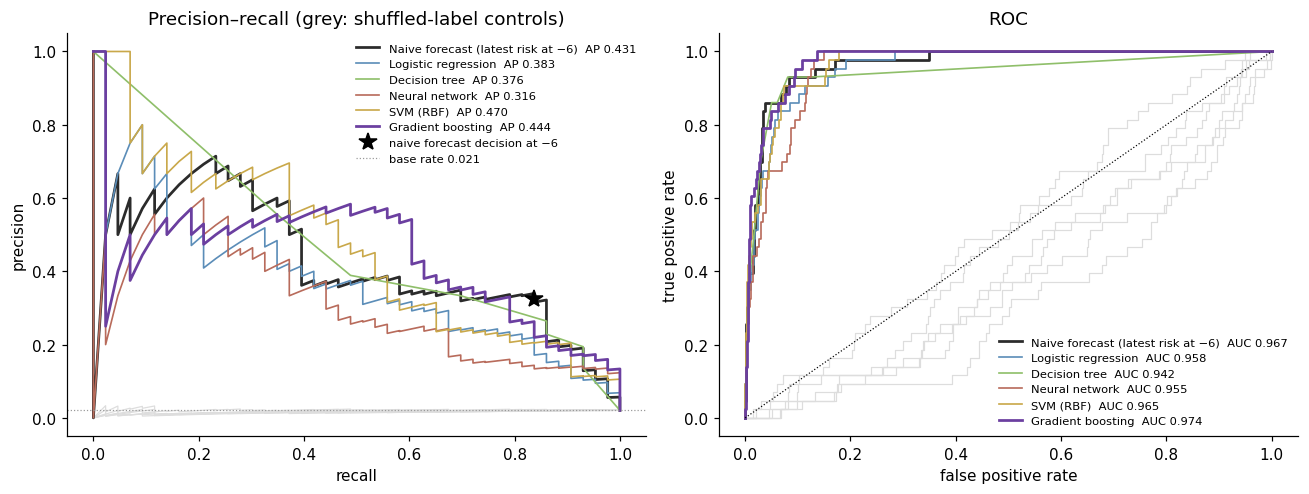

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.2))
for ax, name in zip(axes.ravel(), ["lrp", "lrp_tuned", "logreg", "tree", "nn", "svm", "hgb", "constant"]):
    r = results[name]; cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    ax.imshow(cm, cmap="Purples", vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["predicted low", "predicted high"], fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["actual low", "actual high"], fontsize=8)
    ax.set_title(f"{LABEL[name]}\nrecall {r['recall']:.2f}  precision {r['precision']:.2f}  F2 {r['F2']:.3f}", fontsize=8.5)
fig.suptitle("Confusion matrices on the test split (each model at its own cross-validated threshold)", y=1.01); fig.tight_layout(); plt.show()

COL = {"lrp": "#2B2B2B", "logreg": "#5B8DB8", "tree": "#8FBF6A", "nn": "#B86B5B", "svm": "#C9A84A", "hgb": "#6B3FA0"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for v in ctrl.values():
    p, r_, _ = precision_recall_curve(y_test, np.array(v)); ax[0].plot(r_, p, color="#DDD", lw=0.8)
    fpr, tpr, _ = roc_curve(y_test, np.array(v)); ax[1].plot(fpr, tpr, color="#DDD", lw=0.8)
for name in ["lrp", "logreg", "tree", "nn", "svm", "hgb"]:
    s = test_scores[name]; p, r_, _ = precision_recall_curve(y_test, s); fpr, tpr, _ = roc_curve(y_test, s)
    ax[0].plot(r_, p, color=COL[name], lw=1.8 if name in ("lrp", "hgb") else 1.1, label=f"{LABEL[name]}  AP {results[name]['PR-AUC']:.3f}")
    ax[1].plot(fpr, tpr, color=COL[name], lw=1.8 if name in ("lrp", "hgb") else 1.1, label=f"{LABEL[name]}  AUC {results[name]['ROC-AUC']:.3f}")
ax[0].plot(results["lrp"]["recall"], results["lrp"]["precision"], "k*", ms=12, label="naive forecast decision at −6")
ax[0].axhline(y_test.mean(), color="#999", ls=":", lw=0.8, label=f"base rate {y_test.mean():.3f}")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision–recall (grey: shuffled-label controls)"); ax[0].legend(fontsize=7.5, frameon=False)
ax[1].plot([0, 1], [0, 1], "k:", lw=0.8); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate"); ax[1].set_title("ROC"); ax[1].legend(fontsize=7.5, frameon=False)
fig.tight_layout(); plt.show()

### 6.3 Uncertainty: bootstrap confidence intervals

With only 43 high-risk events in the test split, small differences are noise. The test events are resampled 200 times (with replacement) and PR-AUC and F2 recomputed each time; the 2.5th and 97.5th percentiles give a 95 % interval.

,PR-AUC,F2
Naive forecast (latest risk at −6),"0.431 [0.290, 0.612]","0.636 [0.519, 0.717]"
"Naive forecast, tuned threshold","0.431 [0.290, 0.612]","0.645 [0.537, 0.718]"
Logistic regression,"0.383 [0.246, 0.531]","0.497 [0.385, 0.600]"
Decision tree,"0.376 [0.247, 0.493]","0.465 [0.345, 0.575]"
Neural network,"0.316 [0.200, 0.467]","0.434 [0.305, 0.514]"
SVM (RBF),"0.470 [0.316, 0.617]","0.518 [0.411, 0.601]"
Gradient boosting,"0.444 [0.286, 0.591]","0.594 [0.461, 0.687]"


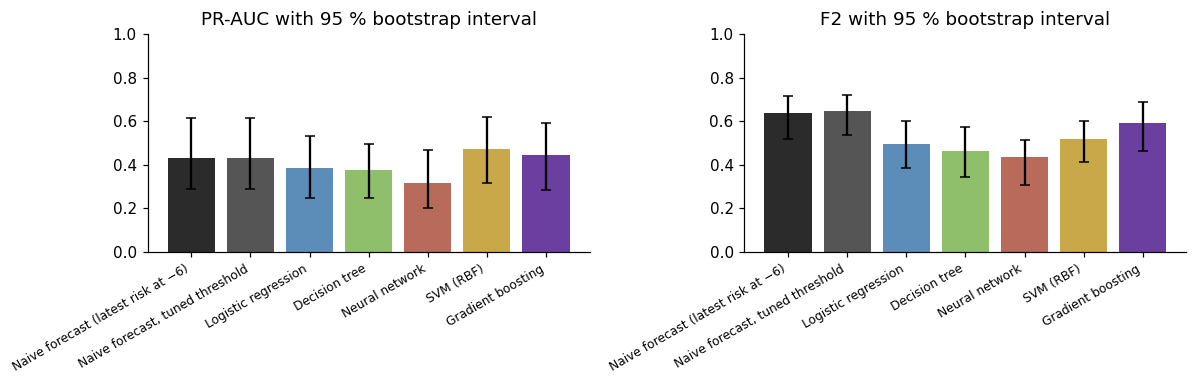

In [20]:
def bootstrap(names, n_boot=200):
    check_budget(); rng = np.random.default_rng(SEED); n = len(y_test); out = {k: {"PR-AUC": [], "F2": []} for k in names}
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if y_test[i].sum() == 0: continue
        for k in names:
            s = np.asarray(test_scores[k])[i]
            out[k]["PR-AUC"].append(average_precision_score(y_test[i], s))
            out[k]["F2"].append(fbeta_score(y_test[i], (s >= thresholds[k]).astype(int), beta=2))
    return {k: {q: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for q, v in d.items()} for k, d in out.items()}
ci = cached_json("bootstrap_ci", lambda: bootstrap(["lrp", "lrp_tuned", "logreg", "tree", "nn", "svm", "hgb"]))
tab = pd.DataFrame({LABEL[k]: {"PR-AUC": f"{results[k]['PR-AUC']:.3f} [{ci[k]['PR-AUC'][0]:.3f}, {ci[k]['PR-AUC'][1]:.3f}]",
                               "F2": f"{results[k]['F2']:.3f} [{ci[k]['F2'][0]:.3f}, {ci[k]['F2'][1]:.3f}]"} for k in ci}).T
display(tab)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, q in zip(ax, ["PR-AUC", "F2"]):
    ks = list(ci); vals = [results[k][q] for k in ks]; lo = [results[k][q] - ci[k][q][0] for k in ks]; hi = [ci[k][q][1] - results[k][q] for k in ks]
    a.bar(range(len(ks)), vals, yerr=[np.maximum(lo, 0), np.maximum(hi, 0)], capsize=3, color=[COL.get(k, "#555") for k in ks])
    a.set_xticks(range(len(ks))); a.set_xticklabels([LABEL[k] for k in ks], rotation=30, ha="right", fontsize=8); a.set_title(f"{q} with 95 % bootstrap interval"); a.set_ylim(0, 1)
fig.tight_layout(); plt.show()

### 6.4 Comparison and model selection

The next cell ranks the models and names the best-performing one on three criteria: the ranking quality (PR-AUC), the alerting quality at the model's own threshold (F2, ESA's metric), and the alerting quality at the naive forecast's number of alerts.

In [21]:
learned = ["logreg", "tree", "nn", "svm", "hgb"]
rank = pd.DataFrame({LABEL[k]: {"PR-AUC": results[k]["PR-AUC"], "F2 (own threshold)": results[k]["F2"],
                                "F2 at naive alert count": results[k]["F2 at naive alert count"], "ROC-AUC": results[k]["ROC-AUC"]} for k in learned}).T
display(rank.round(3).sort_values("PR-AUC", ascending=False))
best = rank["PR-AUC"].idxmax(); best_f2 = rank["F2 (own threshold)"].idxmax(); best_k = rank["F2 at naive alert count"].idxmax()
print(f"On this test split: highest PR-AUC {best} ({rank.loc[best, 'PR-AUC']:.3f}); highest F2 at own threshold {best_f2} "
      f"({rank.loc[best_f2, 'F2 (own threshold)']:.3f}); highest F2 at the naive alert count {best_k} ({rank.loc[best_k, 'F2 at naive alert count']:.3f}).")
print(f"Naive forecast: PR-AUC {results['lrp']['PR-AUC']:.3f}, F2 {results['lrp']['F2']:.3f} (tuned threshold {results['lrp_tuned']['F2']:.3f}).")
beats = [LABEL[k] for k in learned if results[k]["F2"] > results["lrp"]["F2"]]
print("Learned models with a higher F2 than the naive forecast on this split:", ", ".join(beats) if beats else "none")

,PR-AUC,F2 (own threshold),F2 at naive alert count,ROC-AUC
SVM (RBF),0.470,0.518,0.495,0.965
Gradient boosting,0.444,0.594,0.601,0.974
Logistic regression,0.383,0.497,0.512,0.958
Decision tree,0.376,0.465,0.601,0.942
Neural network,0.316,0.434,0.477,0.955


On this test split: highest PR-AUC SVM (RBF) (0.470); highest F2 at own threshold Gradient boosting (0.594); highest F2 at the naive alert count Decision tree (0.601).
Naive forecast: PR-AUC 0.431, F2 0.636 (tuned threshold 0.645).
Learned models with a higher F2 than the naive forecast on this split: none


**Reading the comparison.** The bootstrap intervals overlap heavily: with 43 positive test events, differences of a few hundredths between models are noise, and no learned model is separated from the naive forecast with confidence. The single split therefore cannot settle the ranking on its own; the model selection is made with the 25-fold cross-validation of Section 7.2, which uses the same models and hyperparameters on every fold and compares each model with the naive forecast fold by fold. There, **gradient boosting** is the best learned model on both PR-AUC and F2, and it is selected as the project's model; among the four course models the SVM is the strongest on ranking and the decision tree the strongest on F2. Section 6.5 below repeats the five-fold comparison inside this notebook. The decisive comparison for the project, however, is each model against the naive forecast.

### 6.5 Five-fold cross-validation of the tuned models, inside this notebook

To make the selection independent of one draw of the test split, the same pipeline (preprocessing refitted per fold, threshold by inner cross-validation, tuned hyperparameters) is run on a stratified 5-fold split of all 10,460 events. Each metric is computed within its fold; "wins" counts the folds in which the model beats the naive forecast on the same test events.

In [22]:
def cv_notebook():
    outer = StratifiedKFold(5, shuffle=True, random_state=SEED)
    rows = []
    for k, (tr, te) in enumerate(outer.split(X_all, y_all)):
        ytr, yte = y_all[tr], y_all[te]; rtr, rte = events.risk.values[tr], events.risk.values[te]
        n_fl = int((rte >= HIGH_RISK).sum())
        fold = {"fold": k, "n_test": int(len(te)), "pos_test": int(yte.sum()),
                "lrp": evaluate(yte, rte, HIGH_RISK, proba=False, n_flag=n_fl),
                "lrp_tuned": evaluate(yte, rte, best_f2_threshold(ytr, rtr), proba=False, n_flag=n_fl)}
        for name in MODELS:
            sc, thr, _ = fit_final(name, best_params[name], X_all.iloc[tr], ytr, X_all.iloc[te], tag=f"_cv{k}")
            fold[name] = evaluate(yte, sc, thr, proba=(name != "svm"), n_flag=n_fl)
        rows.append(fold)
    return rows
cv_rows = cached_json("cv5_notebook", cv_notebook)

summary = {}
for name in ["lrp", "lrp_tuned"] + MODELS:
    ap = np.array([r[name]["PR-AUC"] for r in cv_rows]); f2 = np.array([r[name]["F2"] for r in cv_rows]); f2k = np.array([r[name]["F2 at naive alert count"] for r in cv_rows])
    ap0 = np.array([r["lrp"]["PR-AUC"] for r in cv_rows]); f20 = np.array([r["lrp"]["F2"] for r in cv_rows])
    summary[LABEL[name]] = {"PR-AUC": f"{ap.mean():.3f} ± {ap.std():.3f}", "F2": f"{f2.mean():.3f} ± {f2.std():.3f}", "F2 at naive alert count": f"{f2k.mean():.3f}",
                            "PR-AUC vs naive": "" if name == "lrp" else f"{(ap - ap0).mean():+.3f}, wins {(ap > ap0).sum()}/5",
                            "F2 vs naive": "" if name == "lrp" else f"{(f2 - f20).mean():+.3f}, wins {(f2 > f20).sum()}/5"}
print("stratified 5-fold cross-validation of all 10,460 events (" + ", ".join(str(r["pos_test"]) for r in cv_rows) + " high-risk events per fold)")
display(pd.DataFrame(summary).T)

stratified 5-fold cross-validation of all 10,460 events (43, 43, 43, 43, 44 high-risk events per fold)


,PR-AUC,F2,F2 at naive alert count,PR-AUC vs naive,F2 vs naive
Naive forecast (latest risk at −6),0.398 ± 0.105,0.600 ± 0.043,0.600,,
"Naive forecast, tuned threshold",0.398 ± 0.105,0.615 ± 0.042,0.600,"+0.000, wins 0/5","+0.015, wins 5/5"
Logistic regression,0.347 ± 0.071,0.500 ± 0.071,0.507,"-0.052, wins 1/5","-0.100, wins 0/5"
Decision tree,0.363 ± 0.057,0.586 ± 0.058,0.574,"-0.035, wins 1/5","-0.014, wins 2/5"
Neural network,0.333 ± 0.072,0.486 ± 0.054,0.503,"-0.066, wins 1/5","-0.114, wins 0/5"
SVM (RBF),0.419 ± 0.078,0.513 ± 0.048,0.522,"+0.021, wins 2/5","-0.086, wins 0/5"
Gradient boosting,0.484 ± 0.066,0.596 ± 0.034,0.600,"+0.086, wins 4/5","-0.004, wins 2/5"


Over five folds the picture is the same as on ESA's split and in the 25-fold study of Section 7: gradient boosting is the best learned model and is close to the naive forecast on F2; the course models rank below. The selection stands: **gradient boosting** is the project's model, with the naive forecast (plus a tuned threshold) as the operational benchmark it does not clearly beat.

## 7. Robustness checks, insights and reporting

The single 80/20 split above is one draw. The project's scripts (`models.py`, `run_all.sh`) run the same pipeline, with the same preprocessing, models and hyperparameters, on three splits and three feature sets, with paired comparisons against the naive forecast on every fold, and save everything to `results/`. This section loads those results. (They take about two hours to regenerate; `README.md` documents them in full.)

### 7.1 ESA's competition split (the published benchmark: 8,293 training events with 66 high risk, 2,167 test events with 150)

In [23]:
def load_metrics(fs, split):
    p = os.path.join(OUT, f"metrics_{fs}__{split}.json")
    return json.load(open(p)) if os.path.exists(p) else None

M = {(fs, sp): load_metrics(fs, sp) for fs in ("latest", "history", "no_risk") for sp in ("official", "cv", "mission")}
missing = [k for k, v in M.items() if v is None]
if missing:
    print("results not found for", missing, "- run run_all.sh to regenerate; the cells below show what is available")
NAMES = {"lrp": "Naive forecast (−6)", "lrp_tuned": "Naive forecast, tuned threshold", "logreg": "Logistic regression", "tree": "Decision tree",
         "nn": "Neural network (3 seeds)", "svm": "SVM (RBF)", "hgb": "Gradient boosting", "hgb_delta": "Boosting on Δrisk (paper's framing)",
         "constant": "Constant score", "shuffled_control": "Shuffled-label control"}
ROWS = ["lrp", "lrp_tuned", "logreg", "tree", "nn", "svm", "hgb", "hgb_delta", "constant", "shuffled_control"]

def official_table(fs):
    d = M[(fs, "official")]
    if d is None: return None
    s = d["summary"]; f = d["folds"][0]["models"]; rows = {}
    for n in ROWS:
        if n not in s: continue
        c = s[n].get("ci95", {}); r = {"PR-AUC": s[n]["ap"], "PR-AUC 95 % CI": f"[{c['ap'][0]:.3f}, {c['ap'][1]:.3f}]" if c else "",
             "ROC-AUC": s[n]["roc"], "F2": s[n]["f2"], "F2 at naive alert count": s[n].get("f2_at_lrp_rate", np.nan),
             "precision": s[n].get("precision", np.nan), "recall": s[n].get("recall", np.nan)}
        if n in f and "tp" in f[n]:
            n_te = d["folds"][0]["n_test"]; neg = n_te - d["folds"][0]["pos_test"]
            tp, fp, fn = f[n]["tp"], f[n]["fp"], f[n]["fn"]; r["accuracy"] = (tp + (neg - fp)) / n_te
        rows[NAMES[n]] = r
    return pd.DataFrame(rows).T

t = official_table("history")
if t is not None:
    num = [c for c in t.columns if c != "PR-AUC 95 % CI"]; t[num] = t[num].apply(pd.to_numeric).round(3)
    display(t)
    print("Published numbers (Uriot et al. 2022, Table 3): naive forecast F2 0.739; competition winner F2 0.733 with a hand-set threshold cascade, best F2 among the top 10 teams 0.765.")

,PR-AUC,PR-AUC 95 % CI,ROC-AUC,F2,F2 at naive alert count,precision,recall,accuracy
Naive forecast (−6),0.665,"[0.591, 0.739]",0.944,0.739,0.739,0.646,0.767,0.955
"Naive forecast, tuned threshold",0.665,"[0.588, 0.737]",0.944,0.753,0.739,0.641,0.787,0.955
Logistic regression,0.574,"[0.498, 0.653]",0.938,0.651,0.649,0.574,0.673,0.943
Decision tree,0.554,"[0.474, 0.627]",0.912,0.572,0.636,0.701,0.547,0.952
Neural network (3 seeds),0.512,"[0.426, 0.579]",0.914,0.524,0.572,0.509,0.542,0.935
SVM (RBF),0.586,"[0.507, 0.674]",0.934,0.522,0.623,0.594,0.507,0.942
Gradient boosting,0.673,"[0.597, 0.749]",0.950,0.727,0.681,0.586,0.773,0.946
Boosting on Δrisk (paper's framing),0.438,"[0.361, 0.522]",0.883,0.313,0.437,0.745,0.273,0.943
Constant score,0.069,"[0.059, 0.079]",0.500,0.271,0.084,0.069,1.000,0.069
Shuffled-label control,0.060,,0.431,0.233,0.051,NaN,NaN,NaN


Published numbers (Uriot et al. 2022, Table 3): naive forecast F2 0.739; competition winner F2 0.733 with a hand-set threshold cascade, best F2 among the top 10 teams 0.765.


### 7.2 Stratified 5-fold cross-validation (history features: 5 repeats = 25 folds) and satellites held out

Each metric is computed within its fold and averaged; "vs naive" is the paired difference on the same test events and the number of folds in which the model wins.

In [24]:
def cv_table(fs, split):
    d = M[(fs, split)]
    if d is None: return None
    s = d["summary"]; rows = {}
    for n in ROWS:
        if n not in s: continue
        v = s[n].get("vs_lrp", {}); r = {"folds": s[n]["n_folds"], "PR-AUC": f"{s[n]['ap']:.3f} ± {s[n]['ap_sd']:.3f}",
                                         "F2": f"{s[n]['f2']:.3f} ± {s[n]['f2_sd']:.3f}", "F2 at naive alert count": f"{s[n].get('f2_at_lrp_rate', np.nan):.3f}"}
        if v:
            r["PR-AUC vs naive"] = f"{v['ap_diff']:+.3f} ± {v['ap_diff_sd']:.3f}, wins {v['ap_wins']}/{v['n_folds']}"
            r["F2 vs naive"] = f"{v['f2_diff']:+.3f}, wins {v['f2_wins']}/{v['n_folds']}"
        rows[NAMES[n]] = r
    return pd.DataFrame(rows).T

for split, title in (("cv", "Stratified 5-fold cross-validation, history features"), ("mission", "Whole satellites held out (5 folds), history features")):
    t = cv_table("history", split)
    if t is not None:
        print(title); display(t.fillna(""))

Stratified 5-fold cross-validation, history features


,folds,PR-AUC,F2,F2 at naive alert count,PR-AUC vs naive,F2 vs naive
Naive forecast (−6),25,0.394 ± 0.076,0.600 ± 0.041,0.600,,
"Naive forecast, tuned threshold",25,0.394 ± 0.076,0.615 ± 0.036,0.600,"+0.000 ± 0.000, wins 0/25","+0.015, wins 21/25"
Logistic regression,25,0.345 ± 0.074,0.510 ± 0.052,0.505,"-0.049 ± 0.058, wins 6/25","-0.090, wins 1/25"
Decision tree,25,0.347 ± 0.058,0.566 ± 0.041,0.565,"-0.047 ± 0.067, wins 6/25","-0.034, wins 6/25"
Neural network (3 seeds),25,0.332 ± 0.070,0.471 ± 0.058,0.472,"-0.062 ± 0.063, wins 5/25","-0.129, wins 0/25"
SVM (RBF),25,0.410 ± 0.076,0.518 ± 0.043,0.529,"+0.016 ± 0.049, wins 15/25","-0.081, wins 1/25"
Gradient boosting,25,0.474 ± 0.065,0.599 ± 0.039,0.610,"+0.080 ± 0.061, wins 21/25","-0.001, wins 14/25"
Boosting on Δrisk (paper's framing),25,0.386 ± 0.097,0.463 ± 0.087,0.453,"-0.008 ± 0.077, wins 11/25","-0.136, wins 1/25"
Constant score,25,0.021 ± 0.000,0.095 ± 0.001,0.059,"-0.373 ± 0.076, wins 0/25","-0.505, wins 0/25"
Shuffled-label control,5,0.022 ± 0.002,0.093 ± 0.002,0.034,"-0.376 ± 0.106, wins 0/5","-0.507, wins 0/5"


Whole satellites held out (5 folds), history features


,folds,PR-AUC,F2,F2 at naive alert count,PR-AUC vs naive,F2 vs naive
Naive forecast (−6),5,0.353 ± 0.159,0.535 ± 0.200,0.535,,
"Naive forecast, tuned threshold",5,0.353 ± 0.159,0.547 ± 0.207,0.535,"+0.000 ± 0.000, wins 0/5","+0.013, wins 4/5"
Logistic regression,5,0.279 ± 0.140,0.416 ± 0.187,0.410,"-0.074 ± 0.047, wins 0/5","-0.119, wins 0/5"
Decision tree,5,0.295 ± 0.121,0.502 ± 0.195,0.506,"-0.058 ± 0.064, wins 0/5","-0.033, wins 0/5"
Neural network (3 seeds),5,0.249 ± 0.126,0.376 ± 0.175,0.386,"-0.103 ± 0.078, wins 0/5","-0.158, wins 0/5"
SVM (RBF),5,0.330 ± 0.154,0.435 ± 0.177,0.425,"-0.023 ± 0.045, wins 2/5","-0.099, wins 0/5"
Gradient boosting,5,0.412 ± 0.160,0.533 ± 0.200,0.538,"+0.059 ± 0.043, wins 4/5","-0.002, wins 3/5"
Boosting on Δrisk (paper's framing),5,0.351 ± 0.103,0.397 ± 0.134,0.378,"-0.001 ± 0.078, wins 3/5","-0.138, wins 1/5"
Constant score,5,0.021 ± 0.008,0.095 ± 0.033,0.056,"-0.332 ± 0.152, wins 0/5","-0.440, wins 0/5"
Shuffled-label control,5,0.024 ± 0.008,0.088 ± 0.031,0.037,"-0.328 ± 0.153, wins 0/5","-0.447, wins 0/5"


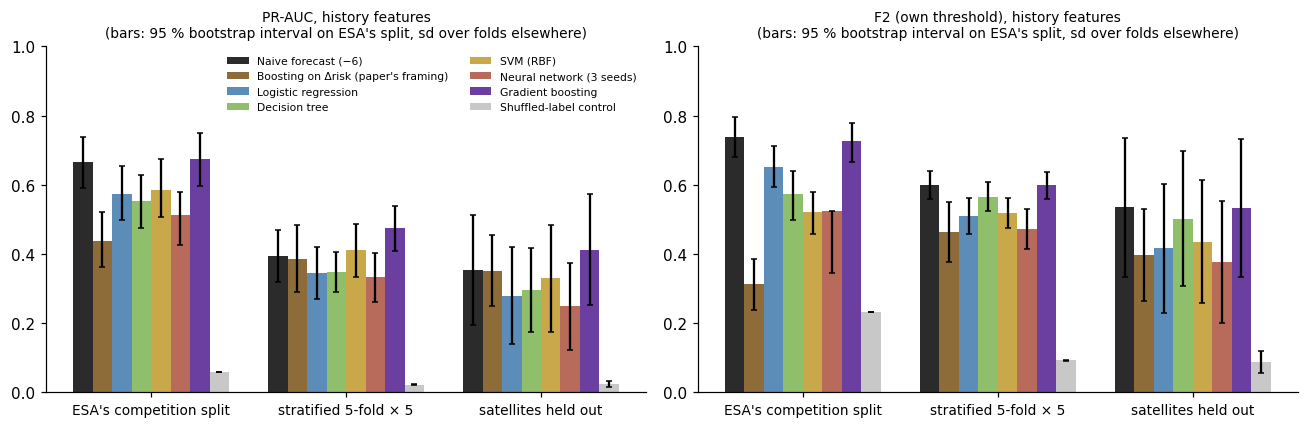

In [25]:
# the three splits side by side, history features
names = ["lrp", "hgb_delta", "logreg", "tree", "svm", "nn", "hgb", "shuffled_control"]
COLS = {"lrp": "#2B2B2B", "hgb_delta": "#8E6C3A", "logreg": "#5B8DB8", "tree": "#8FBF6A", "svm": "#C9A84A", "nn": "#B86B5B", "hgb": "#6B3FA0", "shuffled_control": "#C8C8C8"}
splits = [("official", "ESA's competition split"), ("cv", "stratified 5-fold × 5"), ("mission", "satellites held out")]
if all(M[("history", s)] for s, _ in splits):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, q, ttl in zip(axes, ["ap", "f2"], ["PR-AUC", "F2 (own threshold)"]):
        w = 0.1
        for j, n in enumerate(names):
            vals, lo, hi = [], [], []
            for s_, _ in splits:
                sm = M[("history", s_)]["summary"][n]; vals.append(sm[q])
                c = sm.get("ci95", {}).get(q)
                if s_ == "official" and c:      # single split: 95 % bootstrap interval
                    lo.append(max(0, sm[q] - c[0])); hi.append(max(0, c[1] - sm[q]))
                else:                            # cross-validated: sd over folds
                    lo.append(sm.get(f"{q}_sd", 0)); hi.append(sm.get(f"{q}_sd", 0))
            ax.bar(np.arange(3) + (j - 3.5) * w, vals, w, yerr=[lo, hi], capsize=2, color=COLS[n], label=NAMES[n])
        ax.set_xticks(range(3)); ax.set_xticklabels([t for _, t in splits], fontsize=9); ax.set_ylim(0, 1)
        ax.set_title(ttl + ", history features\n(bars: 95 % bootstrap interval on ESA's split, sd over folds elsewhere)", fontsize=9)
    axes[0].legend(fontsize=7, frameon=False, ncol=2); fig.tight_layout(); plt.show()

### 7.3 Feature sets: does the history help, and what do the other columns know?

In [26]:
rows = {}
for fs, lab in (("latest", "latest CDM only"), ("history", "latest + history"), ("no_risk", "history without any risk column")):
    d = M[(fs, "cv")]
    if d is None: continue
    s = d["summary"]; rows[lab] = {NAMES[n]: f"{s[n]['ap']:.3f} ± {s[n]['ap_sd']:.3f}" for n in ("lrp", "logreg", "tree", "nn", "svm", "hgb", "shuffled_control")}
if rows:
    print("PR-AUC, stratified cross-validation (history: 25 folds, others 5)"); display(pd.DataFrame(rows))

PR-AUC, stratified cross-validation (history: 25 folds, others 5)


,latest CDM only,latest + history,history without any risk column
Naive forecast (−6),0.398 ± 0.105,0.394 ± 0.076,0.398 ± 0.105
Logistic regression,0.336 ± 0.060,0.345 ± 0.074,0.195 ± 0.015
Decision tree,0.339 ± 0.076,0.347 ± 0.058,0.171 ± 0.013
Neural network (3 seeds),0.347 ± 0.068,0.332 ± 0.070,0.227 ± 0.032
SVM (RBF),0.410 ± 0.065,0.410 ± 0.076,0.219 ± 0.035
Gradient boosting,0.461 ± 0.074,0.474 ± 0.065,0.340 ± 0.062
Shuffled-label control,0.023 ± 0.003,0.022 ± 0.002,0.023 ± 0.003


### 7.4 Which features does the best model use? Permutation importance

The columns of the test split are shuffled one at a time and the drop in the best model's PR-AUC is recorded (10 repeats). A large drop means the model relied on that column.

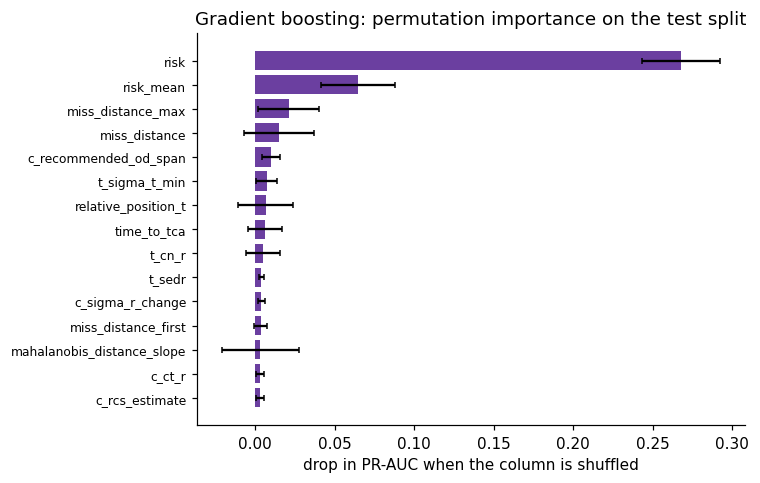

share of the total importance carried by risk-derived columns: 74%


In [27]:
from sklearn.inspection import permutation_importance
def importance():
    check_budget(); pre_, _ = make_preprocessor(X_train, history_cols)
    pipe = Pipeline([("pre", pre_), ("clf", make_model("hgb", **best_params["hgb"]))]).fit(X_train, y_train)
    r = permutation_importance(pipe, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=SEED)
    return {"mean": r.importances_mean.tolist(), "std": r.importances_std.tolist(), "cols": list(history_cols)}
imp = cached_json("importance_hgb", importance)
imp_s = pd.Series(imp["mean"], index=imp["cols"]).sort_values(ascending=False); sd_s = pd.Series(imp["std"], index=imp["cols"])
top = imp_s.head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(range(len(top))[::-1], top.values, xerr=sd_s[top.index].values, color="#6B3FA0", capsize=2)
ax.set_yticks(range(len(top))[::-1]); ax.set_yticklabels(top.index, fontsize=8); ax.set_xlabel("drop in PR-AUC when the column is shuffled")
ax.set_title("Gradient boosting: permutation importance on the test split"); fig.tight_layout(); plt.show()
print(f"share of the total importance carried by risk-derived columns: {imp_s[[c for c in imp_s.index if base_name(c) in RISK_BASES]].clip(lower=0).sum() / imp_s.clip(lower=0).sum():.0%}")

**Feature-selection experiment.** The importance above was measured on the test split, so it cannot be used to choose features. The cell below measures permutation importance on a validation slice of the *training* rows, keeps the 20 most important columns, refits gradient boosting and logistic regression on those 20 alone, and compares them on the test split with the full 167-column versions.

In [28]:
def selection_experiment():
    check_budget()
    a, b = next(StratifiedKFold(4, shuffle=True, random_state=SEED).split(X_train, y_train))   # 75 % fit, 25 % validation, training rows only
    pipe = Pipeline([("pre", make_preprocessor(X_train.iloc[a], history_cols)[0]), ("clf", make_model("hgb", **best_params["hgb"]))]).fit(X_train.iloc[a], y_train[a])
    r = permutation_importance(pipe, X_train.iloc[b], y_train[b], scoring="average_precision", n_repeats=5, random_state=SEED)
    keep = list(pd.Series(r.importances_mean, index=history_cols).sort_values(ascending=False).head(20).index)
    out = {"kept": keep, "results": {}}
    for name in ("hgb", "logreg"):
        for label, cols in (("all 167 columns", history_cols), ("20 selected columns", keep)):
            pre_, _ = make_preprocessor(X_train[cols], cols)
            p = Pipeline([("pre", pre_), ("clf", make_model(name, **best_params[name]))]).fit(X_train[cols], y_train)
            s_ = score_of(p, X_test[cols])
            out["results"][f"{LABEL[name]} | {label}"] = {"PR-AUC": float(average_precision_score(y_test, s_)), "ROC-AUC": float(roc_auc_score(y_test, s_)),
                                                          "F2 at naive alert count": f2_top_k(y_test, s_, n_flag)}
    return out
sel = cached_json("feature_selection", selection_experiment)
print("20 columns kept (training-only permutation importance):", ", ".join(sel["kept"]))
display(pd.DataFrame(sel["results"]).T.round(3))

20 columns kept (training-only permutation importance): risk, risk_mean, mahalanobis_distance, mahalanobis_distance_slope, c_j2k_ecc, relative_position_t, max_risk_estimate, risk_change, c_cndot_n, c_cndot_rdot, t_cd_area_over_mass, miss_distance_max, risk_max, relative_position_n, c_j2k_inc, c_sigma_ndot, risk_std, mahalanobis_distance_max, AP, c_obs_used_min


,PR-AUC,ROC-AUC,F2 at naive alert count
Gradient boosting | all 167 columns,0.444,0.974,0.601
Gradient boosting | 20 selected columns,0.507,0.968,0.548
Logistic regression | all 167 columns,0.383,0.958,0.512
Logistic regression | 20 selected columns,0.371,0.960,0.495


The selected subset is not consistently better: with 20 columns boosting ranks the test events somewhat better (PR-AUC) but produces a slightly worse alert list at the naive forecast's alert count, and logistic regression changes little either way; on 43 positive test events these movements are within noise. The full column set is therefore kept for the final models, and the selection result is read as confirmation that a handful of risk, distance and covariance columns carry almost all of the signal.

### 7.5 The published machine-learning result, re-run

The paper's own experiment (section 6.2) trains a deliberately weak LightGBM regressor on the *change* in risk over 505 stratified 80/20 splits and reports a 1.27 % gain in F2 over the naive forecast. `paper_check.py` repeats it with the paper's exact settings and with two stronger regressors; the saved summary is shown here.

In [29]:
p = os.path.join(OUT, "paper_check.json")
if os.path.exists(p):
    pc = json.load(open(p)); rows = {"Naive forecast": {"F2": f"{pc['lrp_f2_mean']:.4f} ± {pc['lrp_f2_sd']:.4f}", "gain": "", "splits better": "", "mean shift of forecast": "0"}}
    for k in ("lgbm", "hgb_paper", "hgb_ours"):
        if k in pc:
            o = pc[k]; rows[o["settings"]] = {"F2": f"{o['f2_mean']:.4f} ± {o['f2_sd']:.4f}", "gain": f"{o['gain_pct']:+.2f} % (p = {o['p_value']:.1e})",
                                              "splits better": f"{o['splits_better']}/{pc['n_splits']}", "mean shift of forecast": f"{o['mean_abs_shift_of_forecast']:.2f}"}
    print(f"{pc['n_splits']} stratified 80/20 splits; paper: naive 0.5997 ± 0.0439, LightGBM 0.6073 ± 0.0490, +1.27 %")
    display(pd.DataFrame(rows).T)
else:
    print("results/paper_check.json not found (python3 paper_check.py, about 40 min)")

505 stratified 80/20 splits; paper: naive 0.5997 ± 0.0439, LightGBM 0.6073 ± 0.0490, +1.27 %


,F2,gain,splits better,mean shift of forecast
Naive forecast,0.5983 ± 0.0463,,,0
"LightGBM exactly as in the paper (25 trees, lr 0.05, 25 % of features per tree)",0.6042 ± 0.0484,+1.00 % (p = 9.2e-12),326/505,0.14
"sklearn HGB with the paper's settings (25 trees, lr 0.05, 25 % of features)",0.5729 ± 0.0571,-4.24 % (p = 1.2e-37),135/505,0.57
"sklearn HGB with our models.py settings (150 trees, lr 0.1, 15 leaves)",0.4685 ± 0.0677,-21.70 % (p = 7.1e-183),5/505,2.92


### 7.6 Insights

1. **The naive forecast is the model to beat, and no model beats it at the decision point.** On ESA's competition split it reaches F2 0.739; the best learned model, gradient boosting, gets 0.727 at its own threshold (116 of the 150 dangerous events caught against 115, with 82 false alarms against 63) and 0.681 when given the same number of alerts. Over 25 stratified folds boosting's F2 is 0.599 ± 0.039 against the naive forecast's 0.600 ± 0.041, better in 14 folds and worse in 11: a tie. The four course models are 0.03–0.13 below. The one reliable improvement is a slightly lower alert threshold for the naive forecast (−6.04 instead of −6), which the cross-validation finds on its own and which is the first rule of the competition's winning entry.
2. **Gradient boosting ranks events better, by a margin visible only with many folds**: PR-AUC +0.080 ± 0.061 over the naive forecast in the 25-fold study (better in 21 folds), +0.059 with satellites held out (4 of 5), and a near-tie on ESA's split (0.673 vs 0.665). Ranking quality does not turn into a better alert list because the gains sit at recall 0.2–0.5, away from the operating point near recall 0.8.
3. **Hyperparameter tuning helped the course models without changing the ordering.** Strong regularisation won every search (C = 0.01 for logistic regression, 100 rows per leaf for the tree, C = 0.3 with a wide kernel, γ = 0.001, for the SVM), lifting their cross-validated PR-AUC by 0.05–0.07 compared with default-like settings. The SVM is now the best course model on ranking (it ties the naive forecast, +0.016) and the tree the best on F2 (0.566, because it effectively relearns the −6 rule); the network is the weakest and its F2 varies by 0.10 across seeds.
4. **Thresholds do not transfer across base rates.** ESA's training set has 0.8 % high-risk events and its test set 6.9 %; the SVM's own-threshold F2 is 0.10 below what it achieves at the naive forecast's alert count. Probabilities trained with balanced class weights at 0.8 % are not calibrated at 6.9 %: logistic regression and the tree over-predict, boosting and the network are closer to the diagonal.
5. **The other physics carries real but smaller information.** Without any risk column, boosting still reaches PR-AUC 0.34 in cross-validation against 0.02 for the control, so covariance, miss distance and tracking quality do predict the outcome; with the risk columns it reaches 0.47. Permutation importance confirms the latest `risk` dominates, followed by `risk_mean`, `max_risk_scaling` and `miss_distance`, in agreement with the paper's feature-relevance table.
6. **History features add nothing measurable** (0.46 vs 0.47 PR-AUC in cross-validation, 0.70 vs 0.67 on ESA's split): the series mostly repeats its latest value until the last two days, which the model cannot see.
7. **The published 1.3 % gain is real but fragile.** It reproduces (+1.0 %, significant) only with the paper's exact weak LightGBM, which moves the forecast by 0.14 log10 on average; the same recipe in scikit-learn loses 4 % and a normal-strength regressor loses 22 %. On this data the best machine-learning model is one that almost reproduces the naive forecast.
8. **Controls behave.** Shuffled labels give PR-AUC at the base rate and ROC-AUC near 0.5 on every split, so the pipeline does not leak the label.

## 8. Conclusion

The project built a leakage-free event table from ESA's conjunction messages, explored it, engineered history and transformed features, and trained and tuned logistic regression, a decision tree, a neural network, an SVM and gradient boosting to predict whether a close approach will still be dangerous at closest approach. Evaluated with the metrics that matter for a rare-event alert (precision, recall, F1, F2, PR-AUC, ROC-AUC) on a held-out split, on ESA's competition split, on 25 cross-validation folds and on held-out satellites, the models rank events as well as or slightly better than ESA's naive forecast but do not produce a better alert decision than simply trusting the latest risk estimate with a slightly lowered threshold. Gradient boosting is the best of the learned models and ties the naive forecast on F2; among the course's four, the SVM ranks best and the decision tree alerts best, while logistic regression remains the most interpretable. The honest conclusion matches the published analysis of the same competition: the naive forecast is very strong, and the room above it is about one percent of F2, reachable only by models that barely perturb it.

**Limitations.** 216 positive events in total, so confidence intervals are wide; no calendar dates, so a forward-in-time split is impossible; satellites are very unequal, so the mission folds have 15 to 62 positives; features come from the CDMs only, not from what an operator would also know. **Future work** would add calibrated probabilities under the deployment base rate, cost-sensitive thresholds set with ESA's manoeuvre cost, and the time-series models the course did not cover.

### Appendix: files

| file | content |
|---|---|
| `CS465_Project.ipynb` | this notebook (the full pipeline) |
| `data/processed/events.csv.gz` | cleaned, feature-engineered event table (one row per eligible event) |
| `data/processed/features_train.csv.gz`, `features_test.csv.gz` | the scaled, imputed, encoded model inputs for the 80/20 split |
| `results/tuned_params.json`, `results/notebook_test_metrics.csv` | chosen hyperparameters and the test-split metrics table |
| `results/nb_cache/` | cached search, fits, bootstrap and importance (delete to recompute) |
| `get_data.py`, `build_table.py`, `models.py`, `evaluate.py`, `paper_check.py`, `run_all.sh`, `tests/` | the scripted pipeline behind Section 7 and the README |
| `results/metrics_*.json`, `results/RESULTS.md`, `figures/` | the three-split, three-feature-set study |
| `README.md` | full write-up with provenance, manifest and honest limits |